# A Univariate Machine-Learning Approach to Forecasting Sectoral CO₂ Emissions through 2050

Carbon dioxide accounts for roughly four-fifths of global greenhouse-gas emissions, and reliable
forecasts of where those emissions are heading are a prerequisite for climate policy, investment
prioritisation and emission-reduction planning. Forecasting them is difficult: emission paths are
shaped by economic cycles, technological change, policy interventions and unforeseen shocks such as
the 2008 financial crisis and the 2020 pandemic. Most machine-learning work in this area has
examined a single sector or a single country. This study takes a multi-sector, multi-region view,
asking which of four univariate forecasting approaches can be trusted to project each emission
series to 2050. All neural networks are implemented in **PyTorch**.

### Scope of the study

| Dimension | Setting |
|-----------|---------|
| Data source | World Bank World Development Indicators, million tonnes of CO₂ |
| Regions (7) | Brazil (BRA), China (CHN), European Union (EUU), India (IND), Indonesia (IDN), Russia (RUS), United States (USA): the seven largest emitters |
| Sectors (6) | Agriculture (AG), Fugitive emissions (FE), Industrial combustion (IC), Industrial processes (IP), Power (PI), Transportation (TR) |
| Period | 1970–2023 (54 annual observations); earlier years contain substantial gaps that would compromise the analysis |
| Features | Third-degree polynomial of time: $t,\ t^2,\ t^3$ |
| Split | 80/20 chronological: 43 training years (1970–2012), 11 test years (2013–2023); with fewer than 100 observations a separate validation set is not viable |
| Forecast horizon | 2024–2050 |

The approach is deliberately *univariate*: each model sees only the passage of time and the
sector's own emission history. That keeps the models comparable across 42 sector–region series and
isolates the question of which model family extracts the most from limited temporal information.

### Models

| # | Model | Implementation |
|---|-------|----------------|
| 1 | Linear Regression (LR) | Ordinary least squares on the polynomial features (`scikit-learn`) |
| 2 | ARIMA(1,0,0) | Autoregressive model with constant and the polynomial features as exogenous regressors (`statsmodels`) |
| 3 | Shallow Neural Network (SNN) | 1 hidden layer × 100 ReLU neurons (**PyTorch**) |
| 4 | Deep Neural Network (DNN) | 3 hidden layers × 100 ReLU neurons (**PyTorch**) |

Both networks are trained with the Adam optimiser (learning rate 0.001), mean-squared-error loss,
100 epochs and mini-batches of 8, with features and targets standardised by `StandardScaler`.

### Evaluation protocol

Every model is scored with the **mean absolute percentage error (MAPE)** on both the training and
the test window, and must pass two tests before it is considered reliable enough for forecasting:

1. **Overfitting test.** The difference *test MAPE − train MAPE* must be below 10 percentage points.
   A model that has memorised the training years rather than learned the underlying pattern will
   show a large gap. A negative gap (training error above test error) is not a defect; it is a strong
   indication that the model is not overfitting.
2. **Naive benchmark test.** The test MAPE must be lower than that of a *naive* forecast which
   simply carries each year's value forward to the next year. A model that cannot beat "same as
   last year" has not learned anything useful, however small its overfitting gap.

The overfitting test guards against models that fit too closely; the naive test guards against
models whose test error is small in relative terms but still too large to be useful. With 7 regions
and 6 sectors there are 42 candidate models per algorithm. Only those that pass both tests are
retrained on the full 1970–2023 history and used to forecast 2024–2050.

### How to read this notebook

0. Setup: configuration, data download, shared utilities
1. Linear Regression
2. ARIMA
3. Shallow Neural Network
4. Deep Neural Network
5. Cross-model comparison, 2024 forecasts and out-of-sample validation

Run the cells in order. Section 0 must be run before any model section; the model sections are
otherwise independent. LR and ARIMA are deterministic. The neural networks are seeded, so a given
environment reproduces its own results exactly, but their MAPEs can shift slightly across library
versions or hardware because weight initialisation and mini-batch order are drawn from a random stream.

## 0. Setup

### 0.1 Dependencies and imports

In [1]:
# Install the packages that are not part of a standard Colab image. Safe to re-run.
!pip install -q pandas_datareader statsmodels scikit-learn openpyxl torch

In [2]:
import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from pandas_datareader import wb
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

print(f"torch {torch.__version__} | pandas {pd.__version__} | numpy {np.__version__}")

torch 2.11.0+cu130 | pandas 2.2.3 | numpy 2.1.3


### 0.2 Configuration

All experiment-wide constants live here so that the model sections contain no magic numbers.

In [3]:
# World Bank indicator codes, one CO2 series per sector (million tonnes)
INDICATORS = {
    'Agriculture':           'EN.GHG.CO2.AG.MT.CE.AR5',
    'Fugitive_Emissions':    'EN.GHG.CO2.FE.MT.CE.AR5',
    'Industrial_Combustion': 'EN.GHG.CO2.IC.MT.CE.AR5',
    'Industrial_Processes':  'EN.GHG.CO2.IP.MT.CE.AR5',
    'Power':                 'EN.GHG.CO2.PI.MT.CE.AR5',
    'Transportation':        'EN.GHG.CO2.TR.MT.CE.AR5',
}
SECTOR_ABBREV = {'Agriculture': 'AG', 'Fugitive_Emissions': 'FE', 'Industrial_Combustion': 'IC',
                 'Industrial_Processes': 'IP', 'Power': 'PI', 'Transportation': 'TR'}

# Regions, as World Bank ISO3 codes
REGIONS = ['BRA', 'IND', 'CHN', 'USA', 'RUS', 'IDN', 'EUU']
COUNTRY_NAMES = {
    'BRA': 'Brazil', 'IND': 'India', 'CHN': 'China', 'USA': 'United States',
    'RUS': 'Russia', 'IDN': 'Indonesia', 'EUU': 'European Union',
}
# The API returns country *names*; map every variant back to its code.
NAME_TO_CODE = {
    'Brazil': 'BRA', 'India': 'IND', 'China': 'CHN', 'United States': 'USA',
    'Russian Federation': 'RUS', 'Russia': 'RUS', 'Indonesia': 'IDN',
    'European Union': 'EUU', 'EU': 'EUU',
    **{c: c for c in REGIONS},
}

# Time frame
START_YEAR, END_YEAR = 1970, 2023        # historical window used for fitting
FORECAST_END_YEAR    = 2050              # forecasts cover END_YEAR+1 .. FORECAST_END_YEAR
FUTURE_YEARS         = np.arange(END_YEAR + 1, FORECAST_END_YEAR + 1)

# Features and train/test split
POLY_DEGREE    = 3                        # t, t^2, t^3
YEAR_ORIGIN    = START_YEAR               # t is measured in years since 1970, which keeps the features well conditioned
TRAIN_FRACTION = 0.80                     # chronological 80/20 split

# Success criteria
OVERFIT_THRESHOLD = 0.10                  # test MAPE - train MAPE must be below 10 pp
MIN_TRAIN_POINTS, MIN_TEST_POINTS = 10, 5 # skip series with too little data
MAX_MISSING_FRACTION = 0.50               # skip series that are mostly missing

# Neural network hyperparameters, shared by the SNN and the DNN
NN_HIDDEN_UNITS   = 100
NN_EPOCHS         = 100
NN_BATCH_SIZE     = 8
NN_LEARNING_RATE  = 1e-3
SNN_HIDDEN_LAYERS = 1
DNN_HIDDEN_LAYERS = 3

# ARIMA order
ARIMA_ORDER = (1, 0, 0)                   # one autoregressive lag, no differencing, no MA term

# Reproducibility
SEED   = 42
DEVICE = torch.device('cpu')              # CPU keeps results reproducible; the data is tiny

# Sector used for the single-sector walkthrough in each model section
WALKTHROUGH_SECTOR = 'Fugitive_Emissions'


# Output directory for Excel tables and figures
OUTPUT_DIR = 'outputs'
os.makedirs(OUTPUT_DIR, exist_ok=True)

### 0.3 Reproducibility

In [4]:
def set_seed(seed: int = SEED) -> None:
    '''Seed every random number generator used in this notebook.'''
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed()

### 0.4 Data acquisition

The World Bank's World Development Indicators provide one CO₂ series per sector
(`EN.GHG.CO2.<sector>.MT.CE.AR5`, million tonnes). Each sector is downloaded once, the `year`
column is converted from string to integer so it can serve as a numeric temporal feature, the
table is pivoted to one column per region and sorted chronologically, and the result is cached in
the `DATA` dictionary. A copy is written to Excel so the exact data behind a given run is preserved.

In [5]:
def download_sector(indicator_code: str, start: int = START_YEAR, end: int = END_YEAR) -> pd.DataFrame:
    '''Download one indicator for all REGIONS and return a year x region DataFrame.'''
    raw = wb.download(country=REGIONS, indicator=indicator_code, start=start, end=end).reset_index()

    # Identify the three columns regardless of how the API labels them.
    year_col    = next(c for c in raw.columns if 'year' in str(c).lower())
    country_col = next(c for c in raw.columns if 'country' in str(c).lower())
    value_col   = next(c for c in raw.columns if c not in (year_col, country_col))

    raw['year']  = raw[year_col].astype(int)
    raw['value'] = pd.to_numeric(raw[value_col], errors='coerce')

    df = raw.pivot_table(values='value', index='year', columns=country_col).sort_index()
    df = df.rename(columns=NAME_TO_CODE)
    df = df[[r for r in REGIONS if r in df.columns]]      # fixed region order
    df.columns.name = None
    return df


DATA = {}
print('Downloading World Bank data ...')
for sector, code in INDICATORS.items():
    try:
        DATA[sector] = download_sector(code)
        print(f'  {sector:<22} {DATA[sector].shape[0]} years x {DATA[sector].shape[1]} regions')
    except Exception as exc:
        print(f'  {sector:<22} FAILED: {exc}')

if not DATA:
    raise RuntimeError('No data downloaded. Check the network connection and retry.')

with pd.ExcelWriter(f'{OUTPUT_DIR}/co2_sector_data_{START_YEAR}_{END_YEAR}.xlsx') as xw:
    for sector, df in DATA.items():
        df.to_excel(xw, sheet_name=sector)

print(f'\nPreview: {WALKTHROUGH_SECTOR}')
DATA[WALKTHROUGH_SECTOR].head()

  Agriculture            54 years x 7 regions
  Fugitive_Emissions     54 years x 7 regions
  Industrial_Combustion  54 years x 7 regions
  Industrial_Processes   54 years x 7 regions
  Power                  54 years x 7 regions
  Transportation         54 years x 7 regions

Preview: Fugitive_Emissions


,BRA,IND,CHN,USA,RUS,IDN,EUU
year,,,,,,,
1970,9.6518,18.9126,48.3305,350.5993,84.1930,6.3791,236.7718
1971,9.2617,19.0238,48.3227,327.0706,84.1921,6.7451,237.7626
1972,10.1458,19.3944,51.0425,345.9724,85.0371,9.9729,241.8173
1973,11.6142,19.4950,54.3287,403.5284,90.9875,12.5879,250.6980
1974,13.2248,20.7878,57.6671,381.1078,95.3984,14.4147,238.1427


### 0.5 Shared utilities

The steps that are applied identically to every model are implemented once here, so that each model
section contains only the model itself.

* **Polynomial features.** Every model receives the same three inputs, a third-degree polynomial
  of time, which lets it express curvature in the emission path. Higher degrees could capture more
  complex patterns but risk overfitting with only 54 observations. Two numerical conventions are
  used. Linear regression and ARIMA take `[t, t², t³]` with `t` counted from 1970: with raw years
  near 2000 the columns are almost collinear (condition number around 10¹¹) and least-squares and
  maximum-likelihood solvers give machine-dependent answers, whereas with `t` in 0 to 53 the
  condition number is around 10⁴ and every solver returns the same exact solution. The neural
  networks take the raw calendar-year polynomial and standardise it on the training window, which
  is all that gradient descent needs; their results are reproducible across machines as well.
* **Chronological split.** The first 80% of years (1970–2012) train the model, the final 20%
  (2013–2023) test it. Missing values are dropped and the feature matrix truncated to match.
* **Naive benchmark.** Each year's value is shifted forward one year; no equation is involved.
* **Success rule.** A model is reliable only if it beats the naive benchmark on the test set
  *and* its overfitting gap (test MAPE − train MAPE) is below 10 percentage points.
* **Reporting and plotting.** A per-model results table, a per-sector summary, and the
  historical-plus-forecast plot used throughout the study.

In [6]:
_poly = PolynomialFeatures(degree=POLY_DEGREE, include_bias=False)


def make_features(years) -> np.ndarray:
    '''Cubic polynomial time features [t, t^2, t^3] with t = year - YEAR_ORIGIN.

    Used by the linear regression and ARIMA solvers. Measuring t from 1970 keeps the three columns
    well conditioned so that least-squares and maximum-likelihood estimates are exact and identical
    on every machine. It does not change the model: the columns span the same space as the raw
    calendar-year polynomial.
    '''
    t = np.asarray(years, dtype=float) - YEAR_ORIGIN
    return _poly.fit_transform(t.reshape(-1, 1))


def make_nn_features(years) -> np.ndarray:
    '''Cubic polynomial of the raw calendar year, [year, year^2, year^3], for the neural networks.

    The networks standardise their inputs on the training window, which makes gradient descent
    well posed without centring. Over 1970 to 2012 these three columns are almost collinear, so
    after standardisation the network effectively sees a near-linear time index, which is what
    allows it to extrapolate conservatively beyond the training window.
    '''
    return _poly.fit_transform(np.asarray(years, dtype=float).reshape(-1, 1))


def chronological_split(df: pd.DataFrame, region: str):
    '''Return (years_train, years_test, y_train, y_test) for one region, or None if data are insufficient.

    The split point is 80% of the year range, so every region of a sector shares the same
    training and testing years. Missing observations are dropped so that years and values stay
    aligned. Each model builds its own feature matrix from the year arrays.
    '''
    series = df[region]
    if series.isna().mean() > MAX_MISSING_FRACTION:
        return None

    train_size = int(TRAIN_FRACTION * len(series))
    y_train = series.iloc[:train_size].dropna()
    y_test  = series.iloc[train_size:].dropna()
    if len(y_train) < MIN_TRAIN_POINTS or len(y_test) < MIN_TEST_POINTS:
        return None
    return y_train.index.values, y_test.index.values, y_train, y_test


def naive_test_mape(df: pd.DataFrame, region: str, y_test: pd.Series) -> float:
    '''MAPE of the 'same as last year' forecast over the test years.'''
    naive = df[region].shift(1).reindex(y_test.index)
    mask = naive.notna()
    if mask.sum() == 0:
        return np.nan
    return mean_absolute_percentage_error(y_test[mask], naive[mask])


def judge(train_mape: float, test_mape: float, naive_mape: float) -> dict:
    '''Apply the two-part success rule.'''
    gap = test_mape - train_mape
    beats = bool(test_mape < naive_mape) if not np.isnan(naive_mape) else False
    no_overfit = bool(gap < OVERFIT_THRESHOLD)
    return {'Overfitting_Gap': gap, 'Beats_Baseline': beats,
            'No_Overfitting': no_overfit, 'Model_Success': beats and no_overfit}


def evaluate_model(model_name: str, fit_predict, sectors=None, verbose=True) -> pd.DataFrame:
    '''Run one model over every sector x region and return a tidy results table.

    `fit_predict(years_train, y_train, years_eval_list)` must fit a fresh model on the training
    data and return one prediction array for each array of years in `years_eval_list`. Each model
    section provides its own implementation; everything else (splitting, benchmarking, judging)
    is shared.
    '''
    sectors = sectors or list(DATA)
    rows = []
    for sector in sectors:
        df = DATA[sector]
        if verbose:
            print(f'\n=== {model_name}: {sector.replace("_", " ")} ===')
        for region in df.columns:
            split = chronological_split(df, region)
            if split is None:
                if verbose:
                    print(f'  {region}: skipped (insufficient data)')
                continue
            years_train, years_test, y_train, y_test = split

            set_seed()
            train_pred, test_pred = fit_predict(years_train, y_train, [years_train, years_test])

            train_mape = mean_absolute_percentage_error(y_train, train_pred)
            test_mape  = mean_absolute_percentage_error(y_test, test_pred)
            naive_mape = naive_test_mape(df, region, y_test)
            verdict    = judge(train_mape, test_mape, naive_mape)

            rows.append({'Model': model_name, 'Sector': sector, 'Region': region,
                         'Country': COUNTRY_NAMES[region],
                         'Train_MAPE': train_mape, 'Test_MAPE': test_mape,
                         'Naive_Test_MAPE': naive_mape, **verdict})
            if verbose:
                flag = 'PASS' if verdict['Model_Success'] else 'fail'
                print(f'  {region}: train {train_mape:6.2%} | test {test_mape:6.2%} | '
                      f'naive {naive_mape:6.2%} | gap {verdict["Overfitting_Gap"]:+6.2%} | {flag}')
    return pd.DataFrame(rows)


def summarize(results: pd.DataFrame, model_name: str) -> None:
    '''Print the full results table plus success statistics for one model.'''
    fmt = results.copy()
    for col in ['Train_MAPE', 'Test_MAPE', 'Naive_Test_MAPE', 'Overfitting_Gap']:
        fmt[col] = fmt[col].map(lambda v: f'{v:.2%}' if pd.notna(v) else 'N/A')
    cols = ['Sector', 'Country', 'Train_MAPE', 'Test_MAPE', 'Naive_Test_MAPE',
            'Overfitting_Gap', 'Beats_Baseline', 'No_Overfitting', 'Model_Success']

    print(f'\n{"=" * 100}\n{model_name}: results for all sector-region pairs\n{"=" * 100}')
    print(fmt[cols].to_string(index=False))

    n, n_pass = len(results), int(results['Model_Success'].sum())
    print(f'\nPassed both tests : {n_pass}/{n} ({n_pass / n:.1%})')
    print(f'Beat naive benchmark : {int(results["Beats_Baseline"].sum())}/{n}')
    print(f'No overfitting (gap < {OVERFIT_THRESHOLD:.0%}) : {int(results["No_Overfitting"].sum())}/{n}')

    print('\nBy sector:')
    by_sector = results.groupby('Sector')['Model_Success'].agg(['sum', 'count'])
    for sector, row in by_sector.iterrows():
        print(f'  {sector.replace("_", " "):<22} {int(row["sum"])}/{int(row["count"])} passed')

    passed = results[results['Model_Success']]
    if len(passed):
        print('\nSector-region pairs that passed:')
        for _, r in passed.iterrows():
            print(f'  {r["Sector"].replace("_", " "):<22} {r["Country"]:<15} '
                  f'test {r["Test_MAPE"]:.2%} vs naive {r["Naive_Test_MAPE"]:.2%}')


def forecast_full_history(fit_predict, df: pd.DataFrame, region: str) -> pd.Series:
    '''Refit on the entire 1970-2023 history and forecast FUTURE_YEARS.'''
    y = df[region].dropna()
    set_seed()
    (future_pred,) = fit_predict(y.index.values, y, [FUTURE_YEARS])
    return pd.Series(np.asarray(future_pred).ravel(), index=FUTURE_YEARS, name=region)


def plot_forecast(df: pd.DataFrame, region: str, forecast: pd.Series, model_label: str,
                  sector: str, color: str, save: bool = True) -> None:
    '''Historical series plus model forecast for one region.'''
    historical_color = '#2F4B7C'
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.plot(df[region], color=historical_color, linewidth=2.5, marker='o', markersize=3,
            label='Historical (World Bank)')
    ax.plot(forecast, color=color, linewidth=2.5, linestyle='--', dashes=[8, 4],
            marker='s', markersize=3, label=f'{model_label} forecast')
    ax.axvspan(df.index[0], END_YEAR, alpha=0.03, color=historical_color)
    ax.axvspan(END_YEAR + 1, FORECAST_END_YEAR, alpha=0.03, color=color)
    ax.set_title(f'{COUNTRY_NAMES[region]}: {sector.replace("_", " ")} CO₂ emissions ({model_label})',
                 fontsize=14, fontweight='bold')
    ax.set_xlabel('Year'); ax.set_ylabel('Mt CO₂e')
    ax.grid(False); ax.legend(loc='best', framealpha=0.9)
    plt.tight_layout()
    if save:
        tag = model_label.replace(' ', '_').replace('(', '').replace(')', '').replace(',', '')
        fig.savefig(f'{OUTPUT_DIR}/{sector}_{region}_{tag}_forecast.png', dpi=200, bbox_inches='tight')
    plt.show()


def walkthrough(model_name: str, fit_predict, color: str, sector: str = WALKTHROUGH_SECTOR):
    '''Detailed single-sector demonstration: evaluation table, then 2024-2050 forecasts and plots.'''
    df = DATA[sector]
    print(f'{model_name}, {sector.replace("_", " ")} ({df.index[0]}-{df.index[-1]}, '
          f'{int(TRAIN_FRACTION * len(df))} training years, {len(df) - int(TRAIN_FRACTION * len(df))} test years)')

    results = evaluate_model(model_name, fit_predict, sectors=[sector], verbose=False)
    fmt = results.assign(**{c: results[c].map('{:.2%}'.format)
                            for c in ['Train_MAPE', 'Test_MAPE', 'Naive_Test_MAPE', 'Overfitting_Gap']})
    print('\nTest-set performance against the naive benchmark:')
    print(fmt[['Country', 'Train_MAPE', 'Test_MAPE', 'Naive_Test_MAPE', 'Overfitting_Gap',
               'Model_Success']].to_string(index=False))
    print(f'\nAverage test MAPE: {results["Test_MAPE"].mean():.2%} | '
          f'best: {results.loc[results["Test_MAPE"].idxmin(), "Country"]} '
          f'({results["Test_MAPE"].min():.2%}) | worst: {results.loc[results["Test_MAPE"].idxmax(), "Country"]} '
          f'({results["Test_MAPE"].max():.2%})')

    print(f'\nRefitting on the full history and forecasting {FUTURE_YEARS[0]}-{FUTURE_YEARS[-1]} ...')
    forecasts = pd.DataFrame({r: forecast_full_history(fit_predict, df, r) for r in df.columns})
    for region in df.columns:
        plot_forecast(df, region, forecasts[region], model_name, sector, color)

    tag = model_name.replace(' ', '_')
    forecasts.to_excel(f'{OUTPUT_DIR}/{tag}_{sector}_forecasts_{FUTURE_YEARS[0]}_{FUTURE_YEARS[-1]}.xlsx')
    return results, forecasts


print('Shared utilities ready.')

Shared utilities ready.


## 1. Linear Regression

### 1.1 Model

Linear regression expresses the target $y$ as a linear combination of the polynomial features,

$$y = \alpha + \sum_i b_i x_i + \varepsilon,$$

where $\alpha$ is the intercept, $x_i \in \{t, t^2, t^3\}$ are the polynomial features and $b_i$
are the regression coefficients, each giving the change in $y$ for a one-unit change in $x_i$ with
the other features held constant. The coefficients are estimated by ordinary least squares,
minimising $\sum_{i=1}^{n}(y_i - \hat{y}_i)^2$. The solution is closed-form, so the model is
deterministic and trains instantly.

Linear regression is the simplest of the four approaches and the natural reference point. Its
appeal is interpretability and negligible computational cost; its limitation is structural. A fixed
cubic in time can describe a smooth rise, a plateau or a single bend, but it cannot adapt to the
structural shifts (a financial crisis, a pandemic, a policy change) that punctuate many emission
series, and it extrapolates aggressively once it leaves the training window.

In [7]:
def fit_predict_lr(years_train, y_train, years_eval_list):
    '''Fit OLS on the cubic time features and predict for each array of years.'''
    model = LinearRegression().fit(make_features(years_train), np.asarray(y_train, dtype=float))
    return [model.predict(make_features(years)) for years in years_eval_list]


# Inspect the fitted coefficients for one series so the model is concrete.
_t_tr, _t_te, _y_tr, _y_te = chronological_split(DATA[WALKTHROUGH_SECTOR], REGIONS[0])
_lr = LinearRegression().fit(make_features(_t_tr), _y_tr)
print(f'Example: {COUNTRY_NAMES[REGIONS[0]]}, {WALKTHROUGH_SECTOR.replace("_", " ")}:')
print(f'  intercept     : {_lr.intercept_:.4e}')
print(f'  coefficients  : t {_lr.coef_[0]:.4e}, t^2 {_lr.coef_[1]:.4e}, t^3 {_lr.coef_[2]:.4e}')

Example: Brazil, Fugitive Emissions:
  intercept     : 6.7035e+00
  coefficients  : t 2.0308e+00, t^2 -6.0820e-02, t^3 6.7165e-04


### 1.2 Single-sector walkthrough

Train and test MAPE for every region in the walkthrough sector, together with the naive benchmark
and the overfitting gap, followed by 2024–2050 forecasts from a model refitted on the full
1970–2023 history. Plots show the historical series as a solid line and the forecast as a dashed
line, with the two periods lightly shaded.

Linear Regression, Fugitive Emissions (1970-2023, 43 training years, 11 test years)

Test-set performance against the naive benchmark:
       Country Train_MAPE Test_MAPE Naive_Test_MAPE Overfitting_Gap  Model_Success
        Brazil      7.64%    27.73%           5.80%          20.10%          False
         India      6.87%    23.68%           3.75%          16.81%          False
         China     10.43%    32.45%           6.83%          22.02%          False
 United States      4.87%    20.99%           3.38%          16.12%          False
        Russia      6.79%    16.85%           6.55%          10.06%          False
     Indonesia     22.18%    95.53%           4.20%          73.36%          False
European Union      2.58%     4.24%           4.50%           1.65%           True

Average test MAPE: 31.64% | best: European Union (4.24%) | worst: Indonesia (95.53%)

Refitting on the full history and forecasting 2024-2050 ...


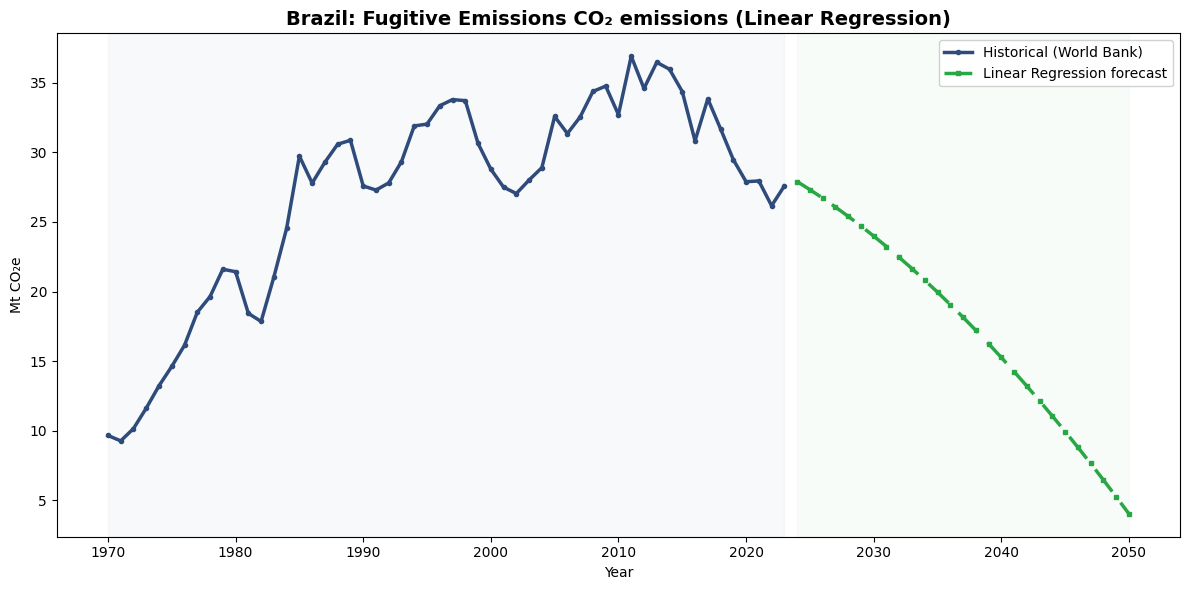

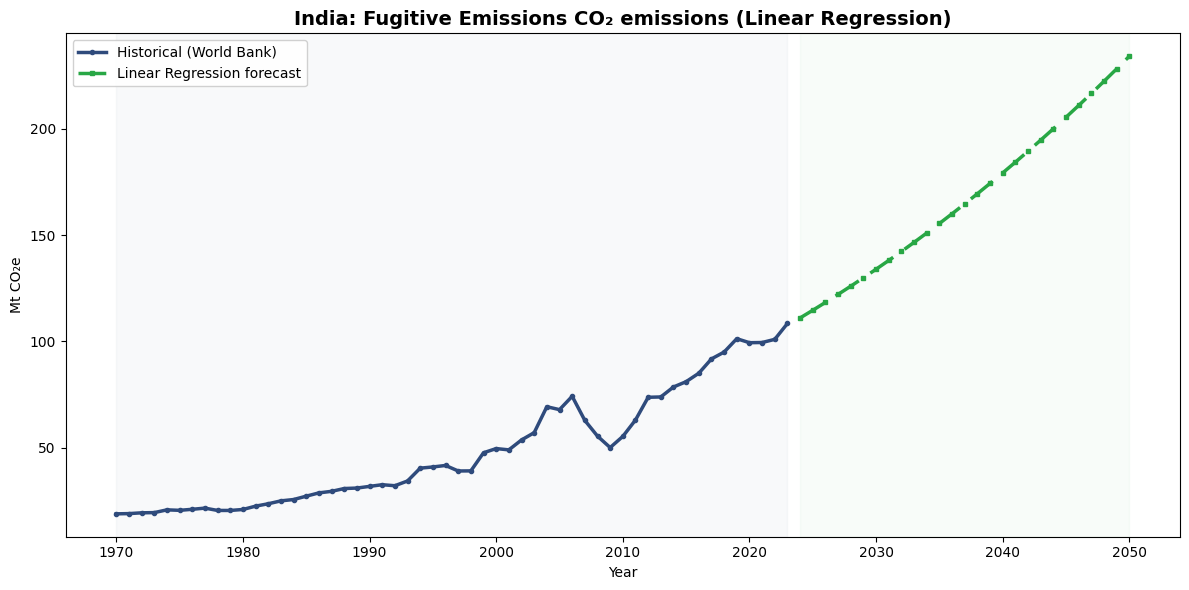

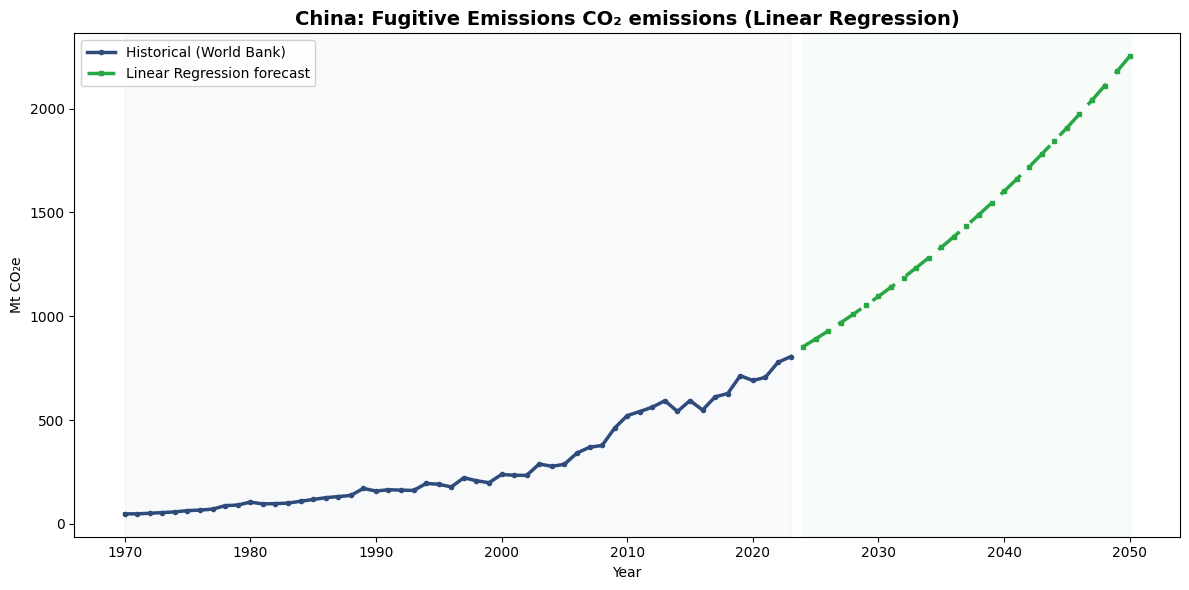

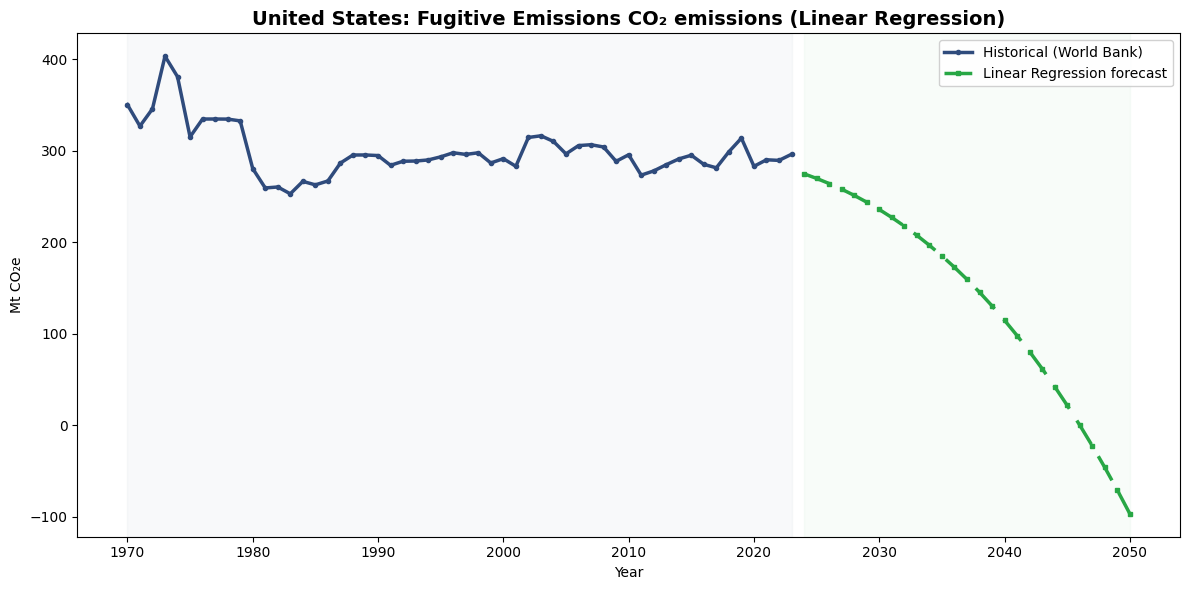

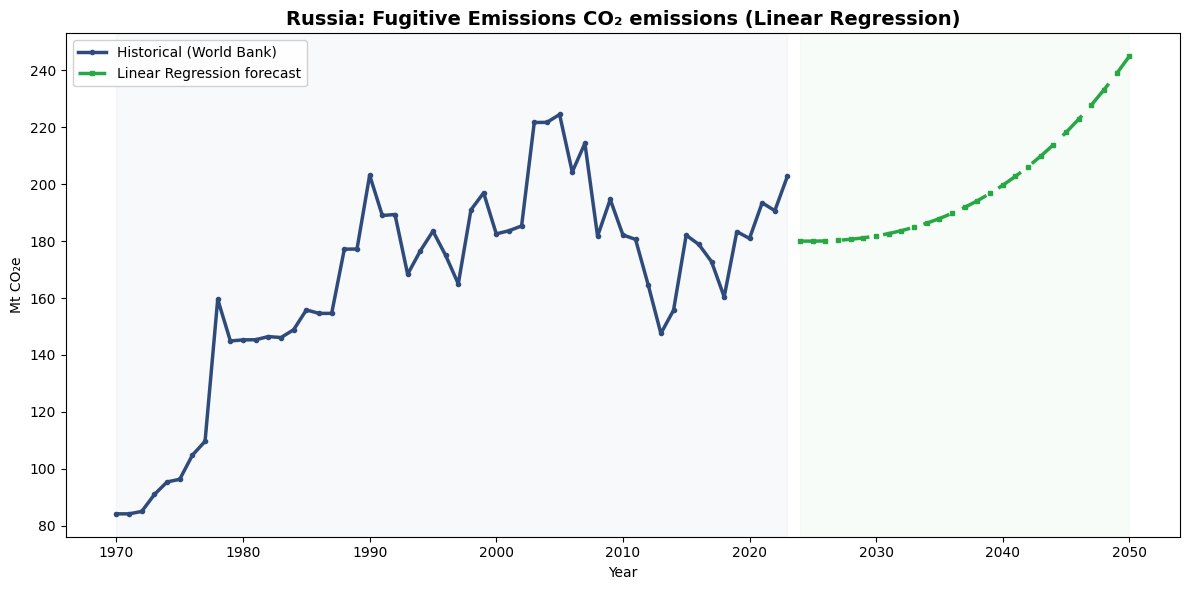

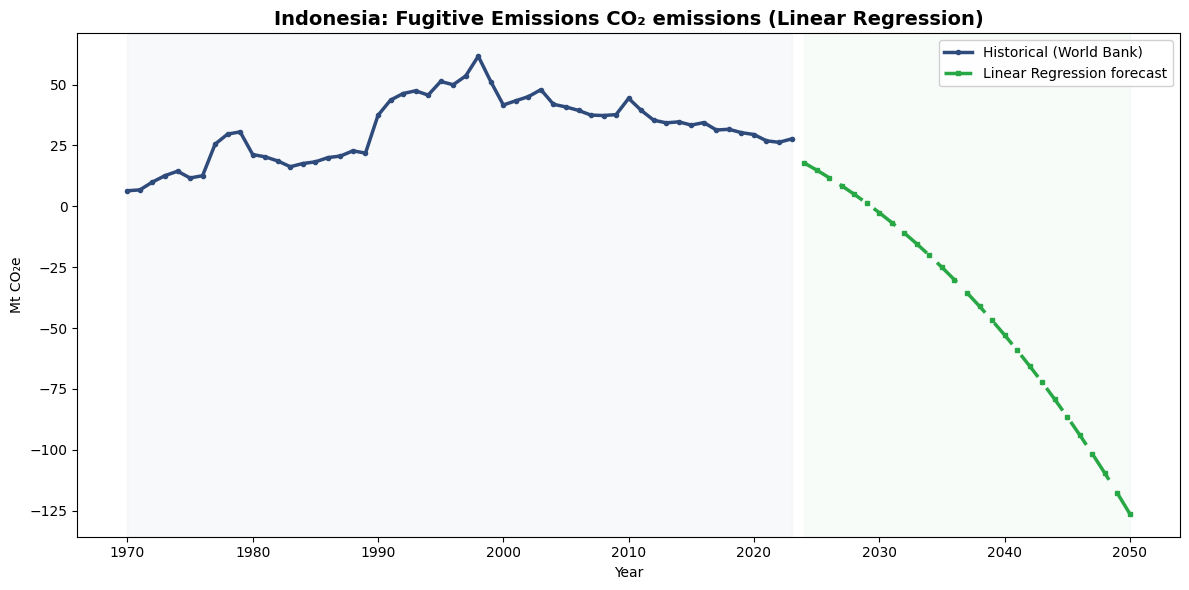

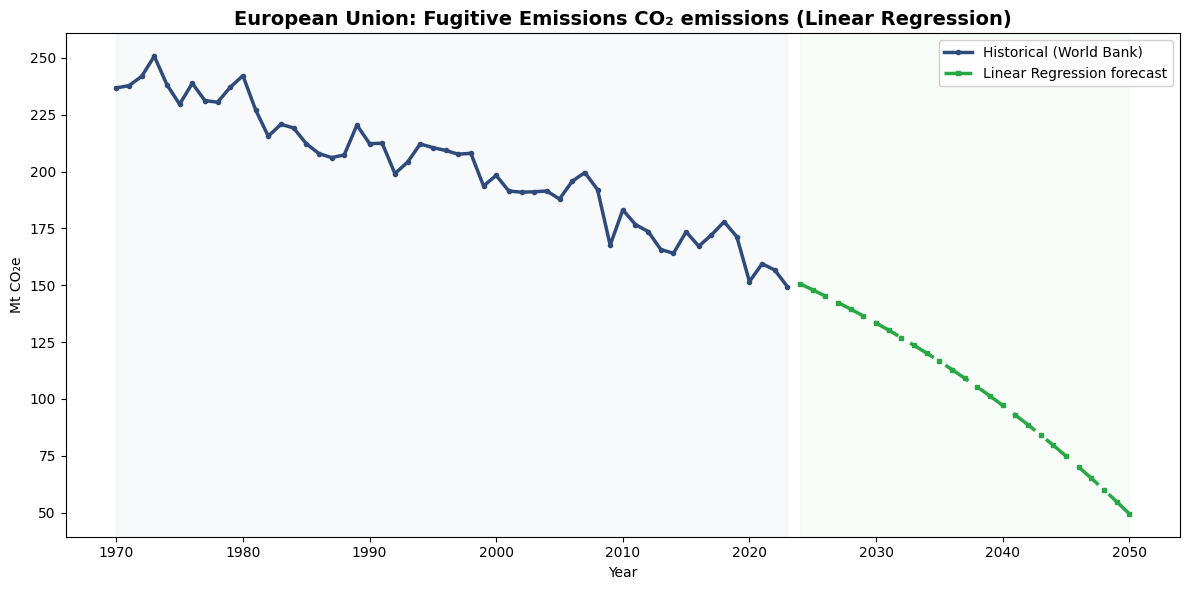

In [8]:
lr_walk_results, lr_walk_forecasts = walkthrough('Linear Regression', fit_predict_lr, color='#28A745')

### 1.3 All sectors and regions

The same procedure applied to all 42 sector–region series. The pass list at the end of the output
identifies the series for which linear regression is a reliable forecaster.

In [9]:
lr_results = evaluate_model('LR', fit_predict_lr)
summarize(lr_results, 'Linear Regression')
lr_results.to_excel(f'{OUTPUT_DIR}/results_LR.xlsx', index=False)


=== LR: Agriculture ===
  BRA: train 12.30% | test  8.12% | naive  5.80% | gap -4.18% | fail
  IND: train  8.08% | test  7.91% | naive  3.70% | gap -0.17% | fail
  CHN: train  8.59% | test 35.13% | naive  9.93% | gap +26.54% | fail
  USA: train  3.80% | test 10.87% | naive  3.12% | gap +7.07% | fail
  RUS: train 10.59% | test 81.22% | naive 14.41% | gap +70.64% | fail
  IDN: train 15.08% | test 25.43% | naive  7.78% | gap +10.34% | fail
  EUU: train  8.08% | test 76.30% | naive  4.54% | gap +68.23% | fail

=== LR: Fugitive Emissions ===
  BRA: train  7.64% | test 27.73% | naive  5.80% | gap +20.10% | fail
  IND: train  6.87% | test 23.68% | naive  3.75% | gap +16.81% | fail
  CHN: train 10.43% | test 32.45% | naive  6.83% | gap +22.02% | fail
  USA: train  4.87% | test 20.99% | naive  3.38% | gap +16.12% | fail
  RUS: train  6.79% | test 16.85% | naive  6.55% | gap +10.06% | fail
  IDN: train 22.18% | test 95.53% | naive  4.20% | gap +73.36% | fail
  EUU: train  2.58% | test  4.24% | 

## 2. ARIMA

### 2.1 Model

ARIMA is governed by three hyper-parameters, the autoregressive order $p$, the differencing
degree $d$ and the moving-average order $q$, which, unlike the model's coefficients, are chosen
by the analyst rather than estimated from the data. With the polynomial features included as
regressors, the model is

$$y(t) = \alpha + \sum_i b_i\, x_i(t) + \sum_k \theta_k\, y(t-k) + \varepsilon(t), \qquad
\varepsilon(t) \sim N(0, \sigma^2),$$

where $x_i(t)$ are the polynomial features at time $t$, $\theta_k$ are the autoregressive
coefficients and $\sigma^2$ is the error variance. This study uses **ARIMA(1,0,0)**: a single
autoregressive lag, no differencing and no moving-average term, together with a constant and
$t, t^2, t^3$ as exogenous regressors. The two components play complementary roles: the polynomial
describes the long-run trajectory of a sector's emissions, while the autoregressive term carries
forward the year-to-year persistence that a smooth trend cannot express.

The order is kept the same for every series rather than searched automatically. With only 54
observations, a specification with one lag and a smooth trend is difficult to overfit, yields stable
and interpretable forecasts, and is well suited to the gradual, largely linear temporal dependence
that characterises emission data. Searching over higher orders and differencing degrees with so few
points tends to produce over-parameterised models and numerically unstable estimates.

Implementation notes

* Training predictions are the in-sample fitted values; test predictions are dynamic multi-step
  forecasts conditioned on the test-period regressors.
* The series is passed to `statsmodels` as a plain array (positional index), which avoids the
  unsupported-index error that newer `statsmodels` versions raise for integer year indices.
* The regressors are the same well-conditioned `t, t², t³` features used by every other model, so
  the maximum-likelihood fit converges to a unique solution and the results are reproducible across
  machines and library versions.

In [10]:
def fit_predict_arima(years_train, y_train, years_eval_list):
    '''Fit ARIMA(1,0,0) with constant and cubic time regressors; return fitted values and forecasts.

    An evaluation array equal to the training years yields the in-sample fitted values; any other
    array is treated as a future horizon and forecast dynamically.
    '''
    X_train = make_features(years_train)
    model = ARIMA(endog=np.asarray(y_train, dtype=float), exog=X_train,
                  order=ARIMA_ORDER, trend='c').fit()
    outputs = []
    for years in years_eval_list:
        if len(years) == len(years_train) and np.array_equal(years, years_train):
            outputs.append(np.asarray(model.fittedvalues))
        else:
            outputs.append(np.asarray(model.forecast(steps=len(years), exog=make_features(years))))
    return outputs


# Show one fitted model so the parameters are visible.
_t_tr, _t_te, _y_tr, _y_te = chronological_split(DATA[WALKTHROUGH_SECTOR], REGIONS[0])
_arima = ARIMA(endog=_y_tr.values, exog=make_features(_t_tr), order=ARIMA_ORDER, trend='c').fit()
print(f'Example: {COUNTRY_NAMES[REGIONS[0]]}, {WALKTHROUGH_SECTOR.replace("_", " ")}:')
print(pd.Series(_arima.params, index=['constant', 't', 't^2', 't^3', 'AR(1) coefficient', 'error variance'])
        .to_string(float_format='{:.6g}'.format))

Example: Brazil, Fugitive Emissions:
constant                 6.7035
t                       2.03081
t^2                  -0.0608202
t^3                 0.000671653
AR(1) coefficient      0.648074
error variance          3.01393


### 2.2 Single-sector walkthrough

The same evaluation and forecasting sequence as for linear regression, applied to every region of
the walkthrough sector.

ARIMA, Fugitive Emissions (1970-2023, 43 training years, 11 test years)

Test-set performance against the naive benchmark:
       Country Train_MAPE Test_MAPE Naive_Test_MAPE Overfitting_Gap  Model_Success
        Brazil      6.17%    27.73%           5.80%          21.56%          False
         India      5.19%    19.96%           3.75%          14.77%          False
         China      7.85%    32.61%           6.83%          24.76%          False
 United States      3.95%    22.23%           3.38%          18.28%          False
        Russia      5.39%    20.86%           6.55%          15.48%          False
     Indonesia     13.82%    89.40%           4.20%          75.58%          False
European Union      2.49%     4.29%           4.50%           1.80%           True

Average test MAPE: 31.01% | best: European Union (4.29%) | worst: Indonesia (89.40%)

Refitting on the full history and forecasting 2024-2050 ...


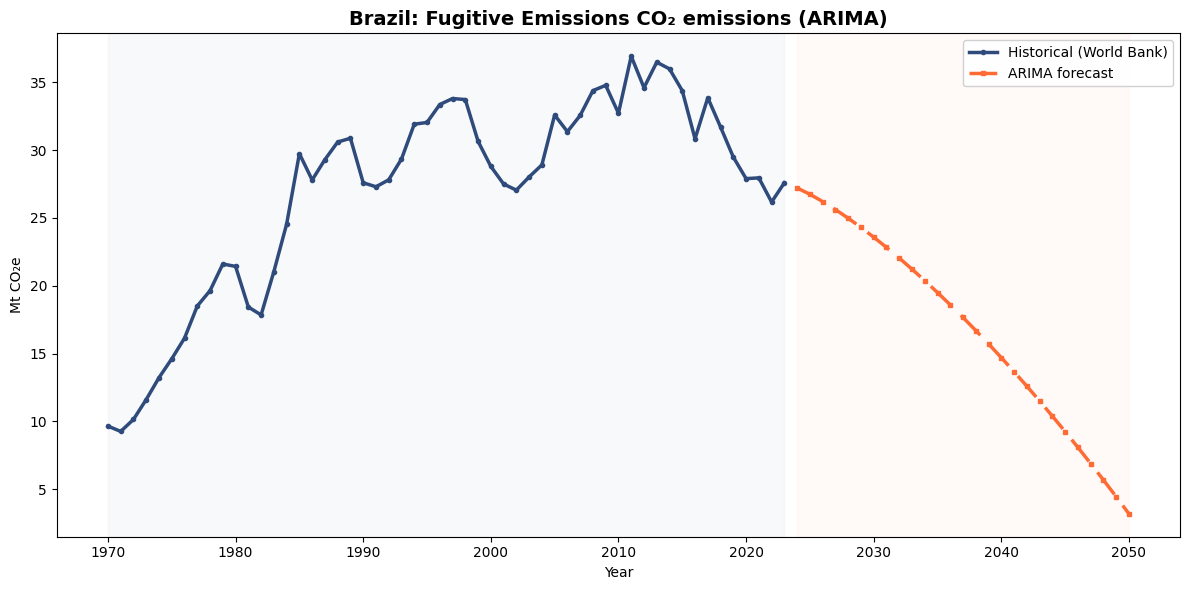

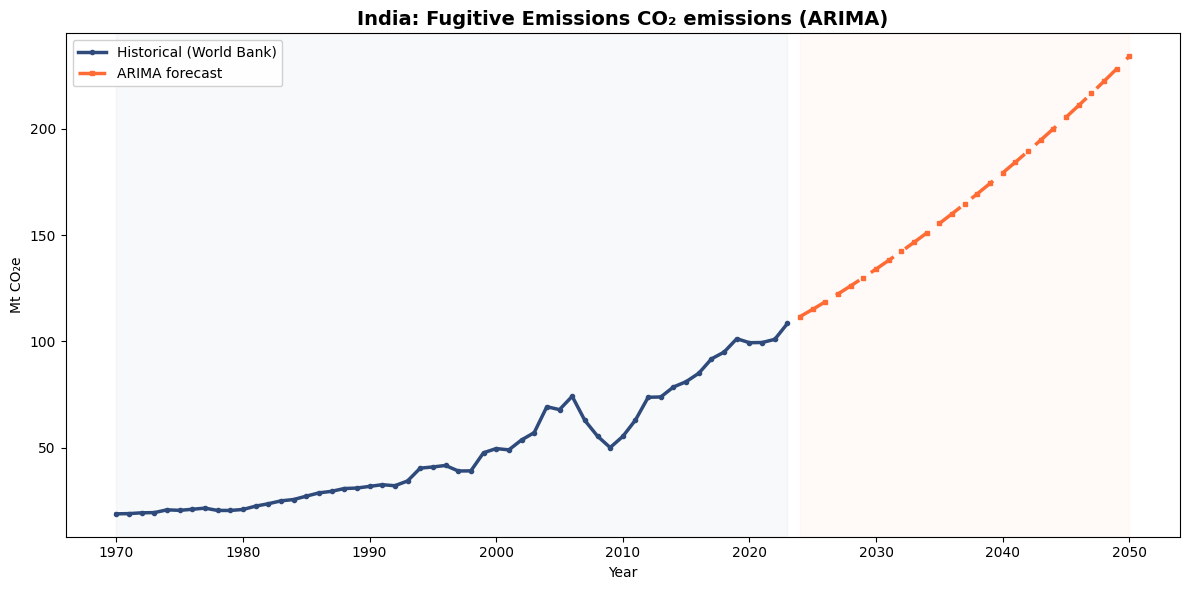

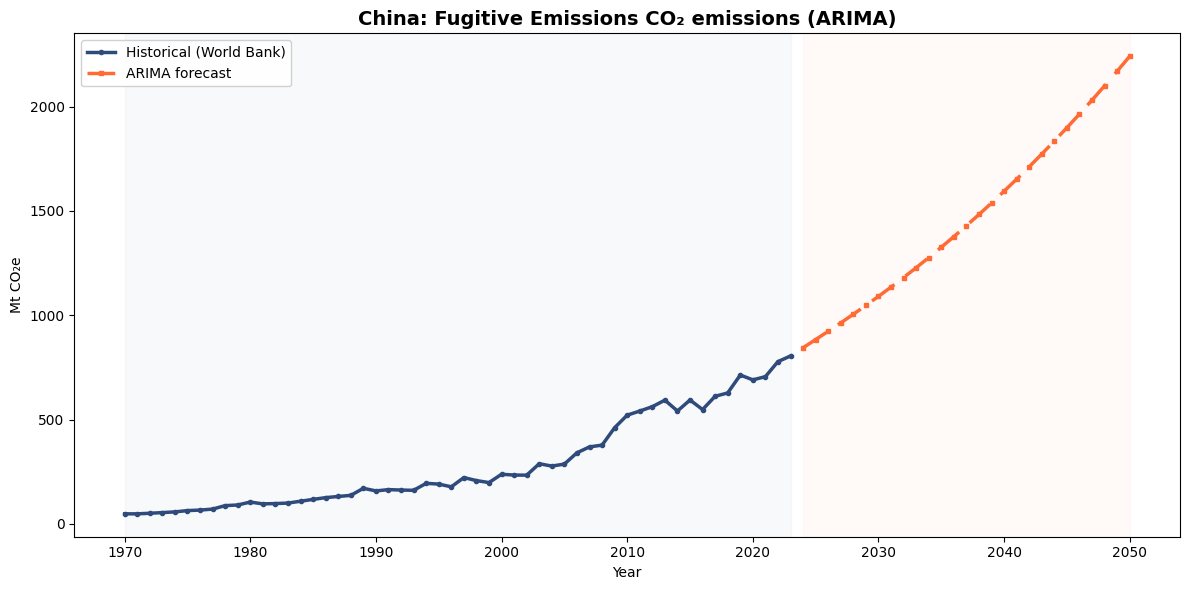

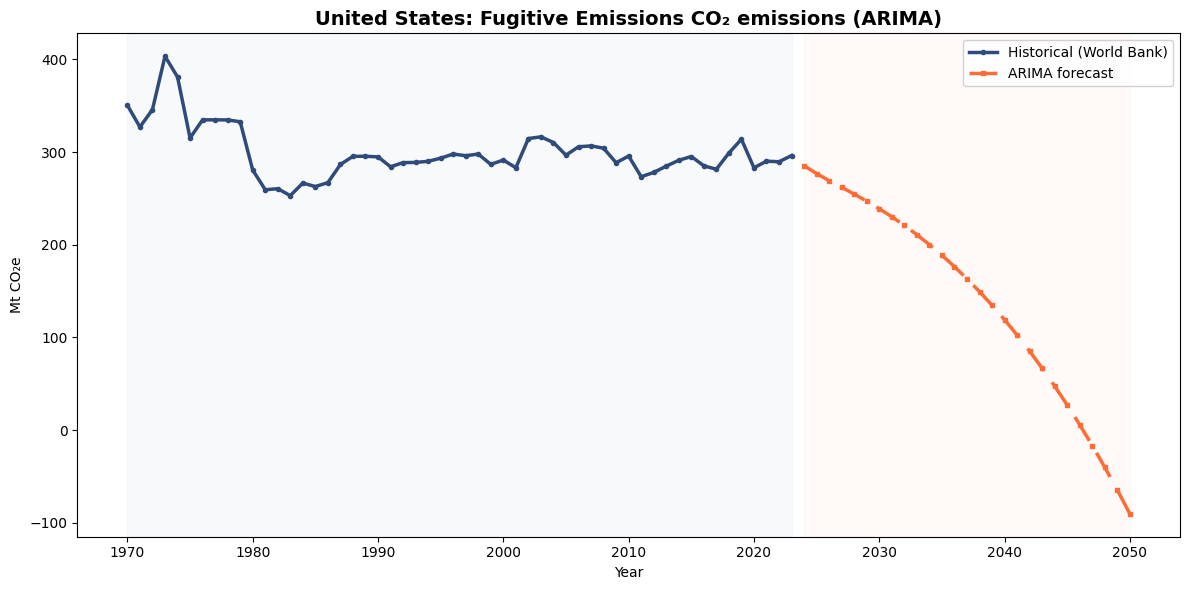

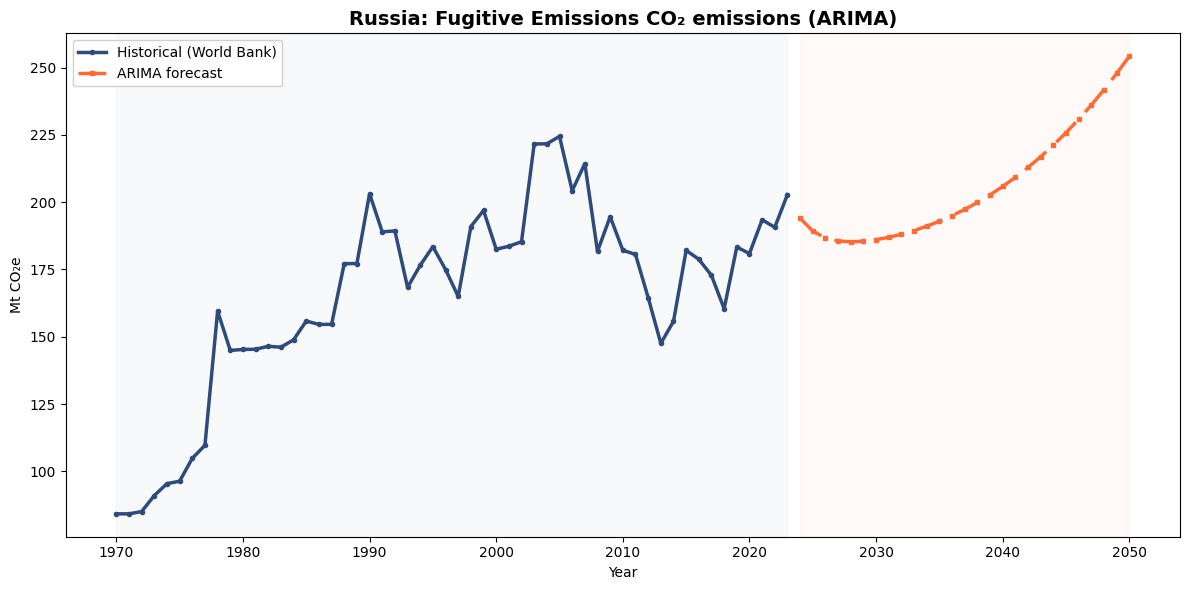

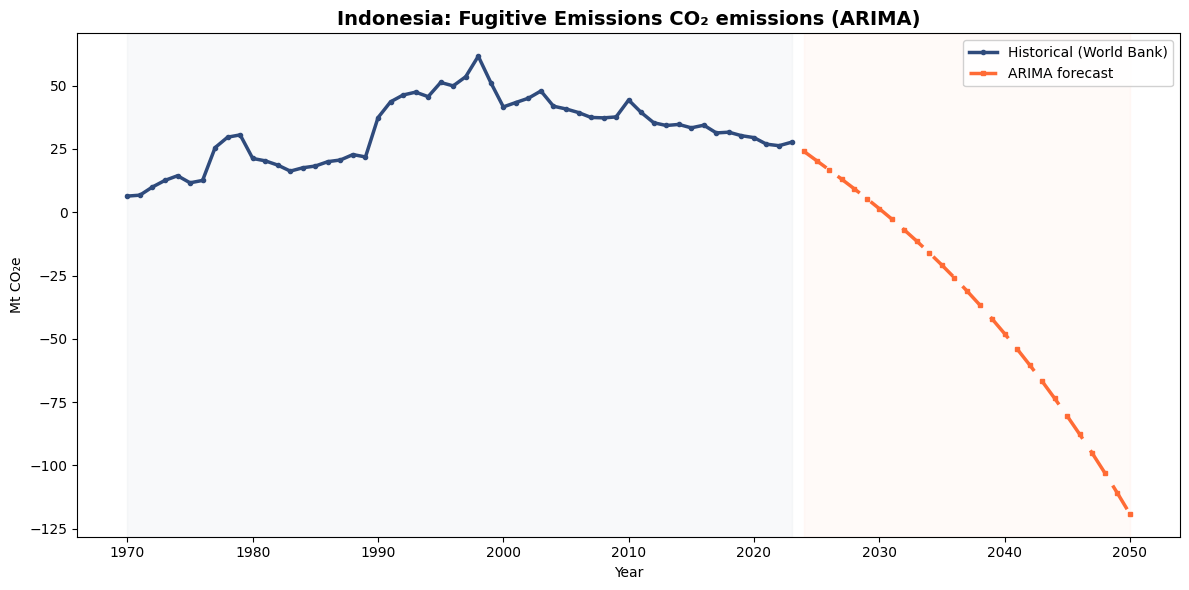

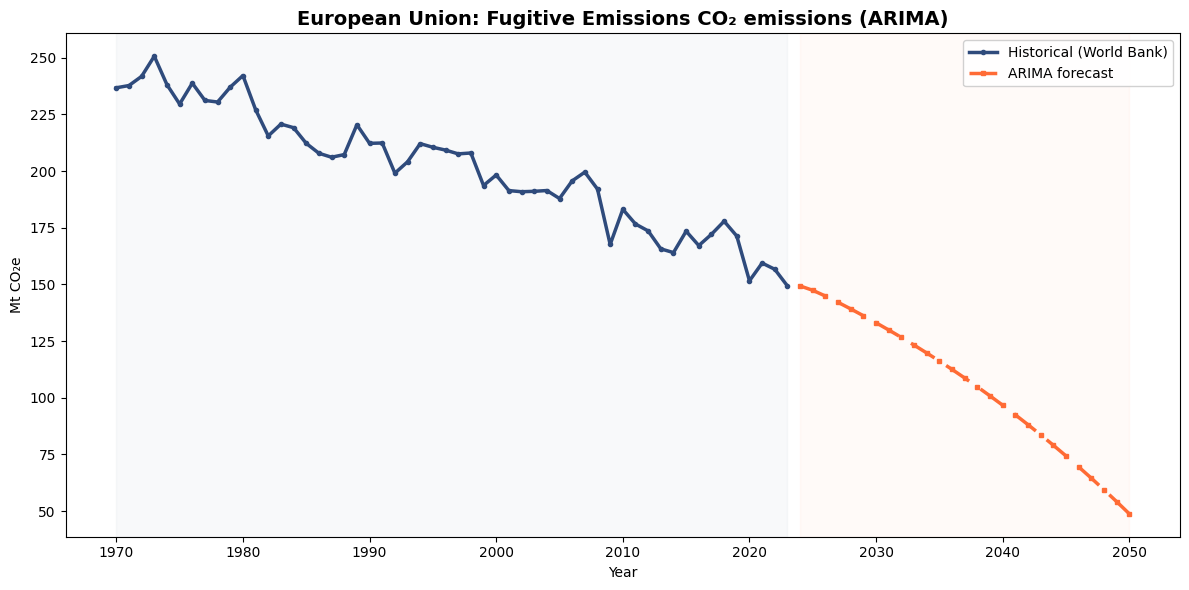

In [11]:
arima_walk_results, arima_walk_forecasts = walkthrough('ARIMA', fit_predict_arima, color='#FF6B35')

### 2.3 All sectors and regions

All 42 series. It is common for ARIMA to show a *negative* overfitting gap (a training MAPE well
above the test MAPE) because the in-sample fitted values include the early years where the
autoregressive term has little history to work with. This is evidence against overfitting rather
than a defect, which is why the two tests are applied together: a model also has to beat the naive
benchmark on the test window.

In [12]:
arima_results = evaluate_model('ARIMA', fit_predict_arima)
summarize(arima_results, 'ARIMA(1,0,0)')
arima_results.to_excel(f'{OUTPUT_DIR}/results_ARIMA.xlsx', index=False)


=== ARIMA: Agriculture ===
  BRA: train 10.60% | test  7.90% | naive  5.80% | gap -2.70% | fail
  IND: train  5.84% | test  8.10% | naive  3.70% | gap +2.26% | fail
  CHN: train  7.82% | test 34.44% | naive  9.93% | gap +26.62% | fail
  USA: train  3.83% | test 10.30% | naive  3.12% | gap +6.47% | fail
  RUS: train  6.64% | test 74.03% | naive 14.41% | gap +67.39% | fail
  IDN: train 11.46% | test 25.78% | naive  7.78% | gap +14.32% | fail
  EUU: train  4.93% | test 71.56% | naive  4.54% | gap +66.63% | fail

=== ARIMA: Fugitive Emissions ===
  BRA: train  6.17% | test 27.73% | naive  5.80% | gap +21.56% | fail
  IND: train  5.19% | test 19.96% | naive  3.75% | gap +14.77% | fail
  CHN: train  7.85% | test 32.61% | naive  6.83% | gap +24.76% | fail
  USA: train  3.95% | test 22.23% | naive  3.38% | gap +18.28% | fail
  RUS: train  5.39% | test 20.86% | naive  6.55% | gap +15.48% | fail
  IDN: train 13.82% | test 89.40% | naive  4.20% | gap +75.58% | fail
  EUU: train  2.49% | test  4.

## 3. Shallow Neural Network (PyTorch)

### 3.1 Neural-network utilities (shared with Section 4)

Both networks are sequential feed-forward architectures in which information flows from the three
polynomial inputs through the hidden layer(s) to a single output neuron. They differ only in depth,
so construction, training and prediction are written once here and parameterised by the number of
hidden layers.

Four hyper-parameters define the networks: 100 neurons per hidden layer, ReLU activation, 100
training epochs and a batch size of 8. Training uses the Adam optimiser at a learning rate of 0.001,
an extension of stochastic gradient descent that updates weights iteratively from mini-batches
and is computationally efficient with low memory requirements, with mean-squared-error loss and
the data reshuffled every epoch. Features and targets are standardised with `StandardScaler`, which
stabilises and accelerates training and reduces the likelihood of overfitting on a 54-point series.
Weights are initialised with the Glorot-uniform scheme and zero biases. Predictions are mapped back
to the original Mt CO₂ scale before any error is computed.

In [13]:
def build_mlp(input_dim: int, hidden_layers: int, units: int = NN_HIDDEN_UNITS) -> nn.Sequential:
    '''Fully connected ReLU network: `hidden_layers` x `units`, single linear output.'''
    layers, in_dim = [], input_dim
    for _ in range(hidden_layers):
        layers += [nn.Linear(in_dim, units), nn.ReLU()]
        in_dim = units
    layers.append(nn.Linear(in_dim, 1))
    model = nn.Sequential(*layers)
    for layer in model:
        if isinstance(layer, nn.Linear):
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)
    return model.to(DEVICE)


def train_mlp(model: nn.Module, X: np.ndarray, y: np.ndarray,
              epochs: int = NN_EPOCHS, batch_size: int = NN_BATCH_SIZE,
              lr: float = NN_LEARNING_RATE, verbose: bool = False) -> list:
    '''Mini-batch Adam / MSE training loop. Returns the per-epoch training loss.'''
    X_t = torch.as_tensor(X, dtype=torch.float32, device=DEVICE)
    y_t = torch.as_tensor(y, dtype=torch.float32, device=DEVICE).reshape(-1, 1)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, eps=1e-7)
    loss_fn = nn.MSELoss()
    n, history = len(X_t), []

    model.train()
    for epoch in range(epochs):
        perm, running = torch.randperm(n), 0.0
        for start in range(0, n, batch_size):
            idx = perm[start:start + batch_size]
            optimizer.zero_grad()
            loss = loss_fn(model(X_t[idx]), y_t[idx])
            loss.backward()
            optimizer.step()
            running += loss.item() * len(idx)
        history.append(running / n)
        if verbose and (epoch + 1) % 20 == 0:
            print(f'    epoch {epoch + 1:3d}/{epochs}  loss {history[-1]:.4f}')
    return history


def predict_mlp(model: nn.Module, X: np.ndarray) -> np.ndarray:
    '''Forward pass without gradients; returns a flat NumPy array.'''
    model.eval()
    with torch.no_grad():
        return model(torch.as_tensor(X, dtype=torch.float32, device=DEVICE)).cpu().numpy().ravel()


def make_nn_fit_predict(hidden_layers: int):
    '''Factory returning a fit_predict function for an MLP with the given depth.

    Standardisation is fitted on the training window only, so no information from the
    evaluation/forecast period leaks into the model.
    '''
    def fit_predict(years_train, y_train, years_eval_list):
        X_train = make_nn_features(years_train)
        x_scaler = StandardScaler().fit(X_train)
        y_scaler = StandardScaler().fit(np.asarray(y_train, dtype=float).reshape(-1, 1))

        model = build_mlp(X_train.shape[1], hidden_layers)
        train_mlp(model,
                  x_scaler.transform(X_train),
                  y_scaler.transform(np.asarray(y_train, dtype=float).reshape(-1, 1)).ravel())

        return [y_scaler.inverse_transform(
                    predict_mlp(model, x_scaler.transform(make_nn_features(years))).reshape(-1, 1)).ravel()
                for years in years_eval_list]
    return fit_predict


fit_predict_snn = make_nn_fit_predict(SNN_HIDDEN_LAYERS)
fit_predict_dnn = make_nn_fit_predict(DNN_HIDDEN_LAYERS)
print('Neural-network utilities ready.')

Neural-network utilities ready.


### 3.2 Model

One hidden layer of 100 ReLU neurons followed by a linear output, 501 trainable parameters in total.

A single hidden layer is a compromise between complexity and generalisation. It can bend the cubic
trend into a piecewise-linear curve and so capture non-linear relationships that linear regression
cannot, while its limited capacity, reduced variance and simple training dynamics keep the
overfitting risk that comes with deeper networks in check on a short series.

Sequential(
  (0): Linear(in_features=3, out_features=100, bias=True)
  (1): ReLU()
  (2): Linear(in_features=100, out_features=1, bias=True)
)
Trainable parameters: 501

Training trace: Brazil, Fugitive Emissions:
    epoch  20/100  loss 0.1068
    epoch  40/100  loss 0.0853
    epoch  60/100  loss 0.0796
    epoch  80/100  loss 0.0770
    epoch 100/100  loss 0.0763


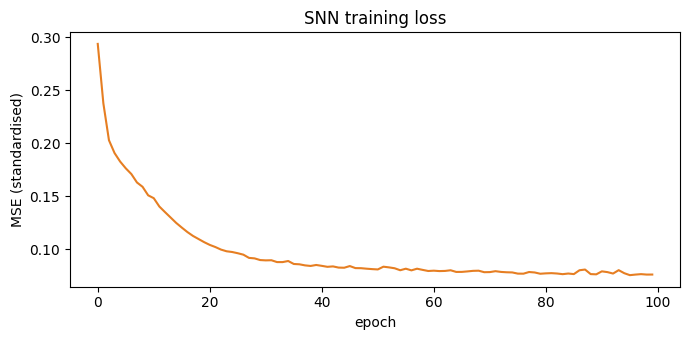

In [14]:
set_seed()
_snn = build_mlp(POLY_DEGREE, SNN_HIDDEN_LAYERS)
print(_snn)
print('Trainable parameters:', sum(p.numel() for p in _snn.parameters()))

# Training-loss trace for one series, to confirm the optimiser converges in 100 epochs.
_t_tr, _t_te, _y_tr, _y_te = chronological_split(DATA[WALKTHROUGH_SECTOR], REGIONS[0])
_X_tr = make_nn_features(_t_tr)
_xs, _ys = StandardScaler().fit(_X_tr), StandardScaler().fit(_y_tr.values.reshape(-1, 1))
print(f'\nTraining trace: {COUNTRY_NAMES[REGIONS[0]]}, {WALKTHROUGH_SECTOR.replace("_", " ")}:')
_hist = train_mlp(_snn, _xs.transform(_X_tr), _ys.transform(_y_tr.values.reshape(-1, 1)).ravel(), verbose=True)
plt.figure(figsize=(7, 3.5)); plt.plot(_hist, color='#E67E22'); plt.xlabel('epoch'); plt.ylabel('MSE (standardised)')
plt.title('SNN training loss'); plt.tight_layout(); plt.show()

### 3.3 Single-sector walkthrough

Each region's network is trained from a fresh seed on the 1970–2012 window and scored on
2013–2023; the networks are then retrained on the full history to produce the 2024–2050 forecasts.

SNN, Fugitive Emissions (1970-2023, 43 training years, 11 test years)

Test-set performance against the naive benchmark:
       Country Train_MAPE Test_MAPE Naive_Test_MAPE Overfitting_Gap  Model_Success
        Brazil      6.97%    17.62%           5.80%          10.65%          False
         India      6.05%    16.15%           3.75%          10.10%          False
         China      7.27%     4.50%           6.83%          -2.77%           True
 United States      4.85%     3.62%           3.38%          -1.23%          False
        Russia      6.74%    12.18%           6.55%           5.43%          False
     Indonesia     16.38%     3.52%           4.20%         -12.86%           True
European Union      2.56%     4.72%           4.50%           2.16%          False

Average test MAPE: 8.90% | best: Indonesia (3.52%) | worst: Brazil (17.62%)

Refitting on the full history and forecasting 2024-2050 ...


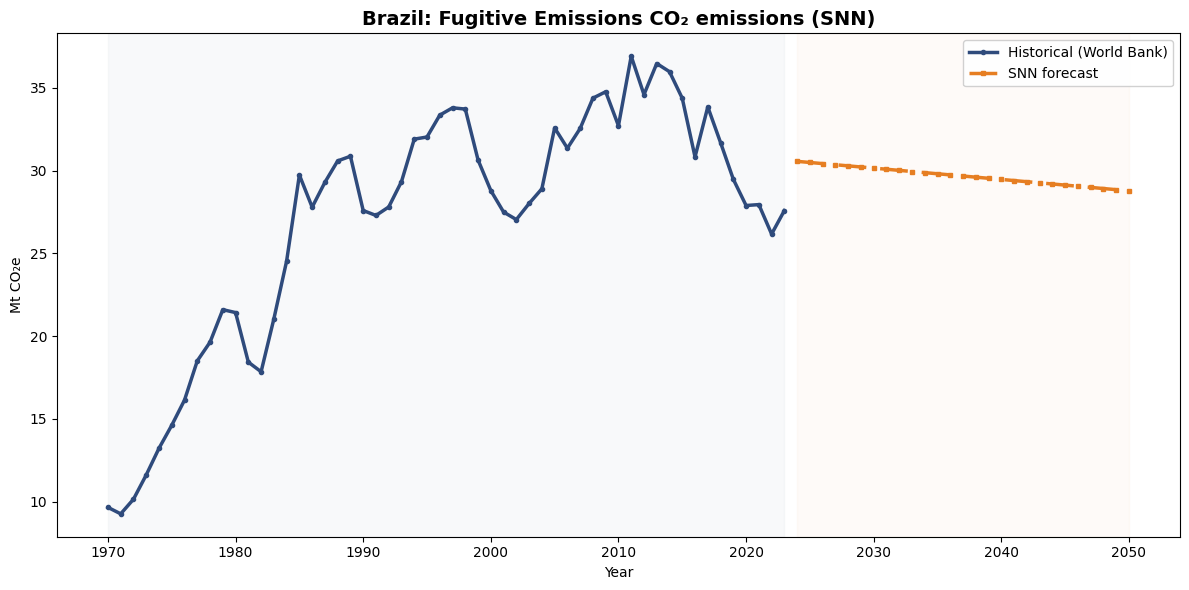

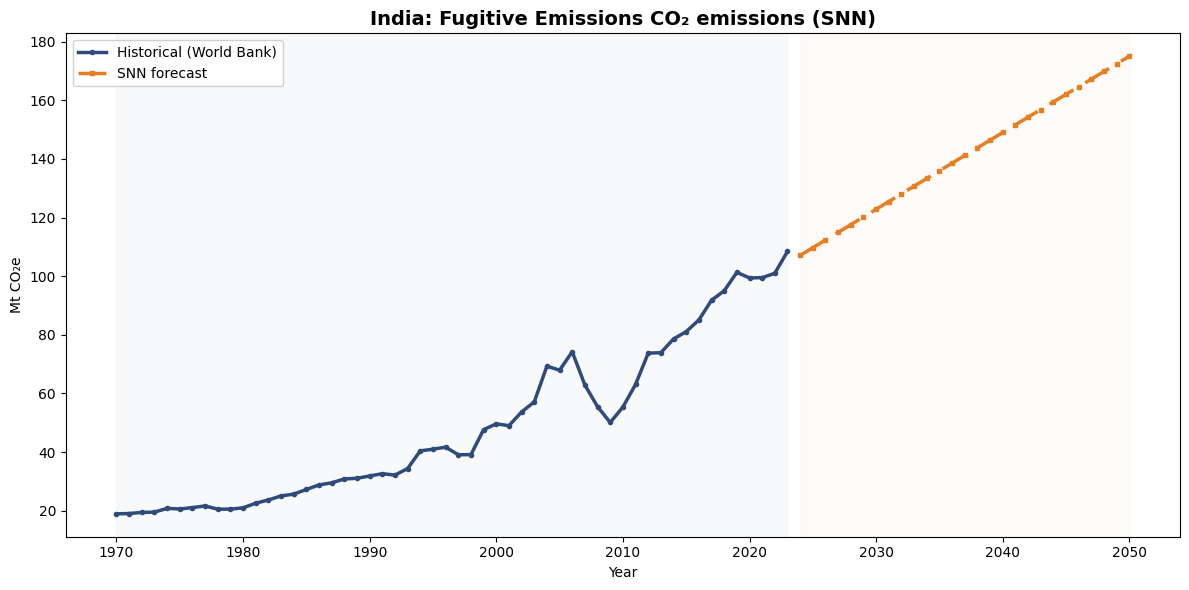

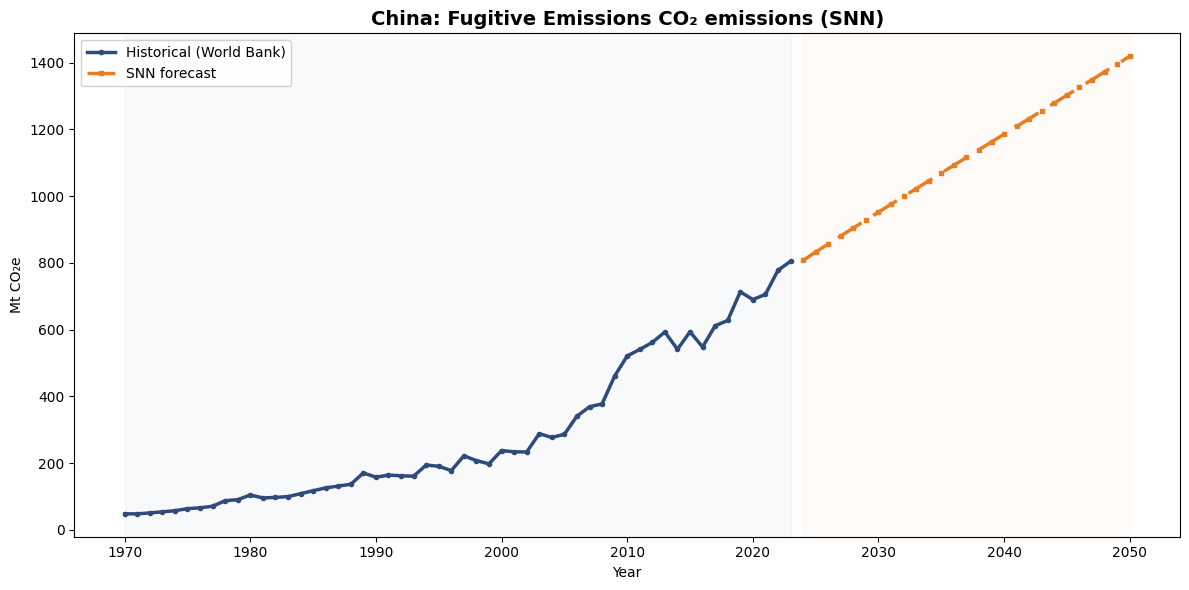

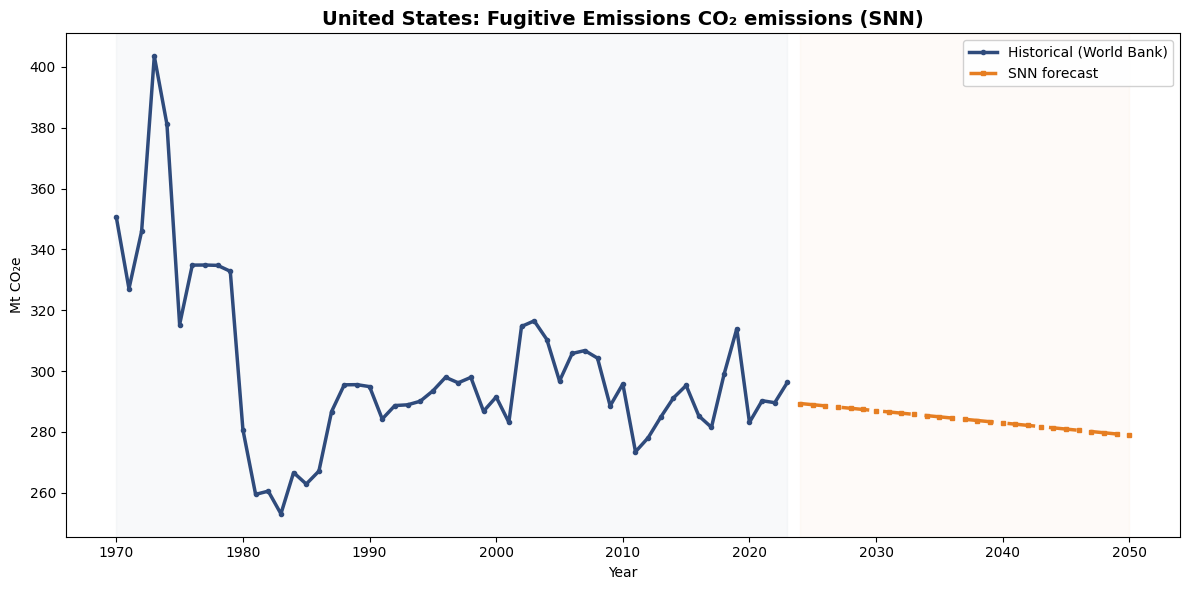

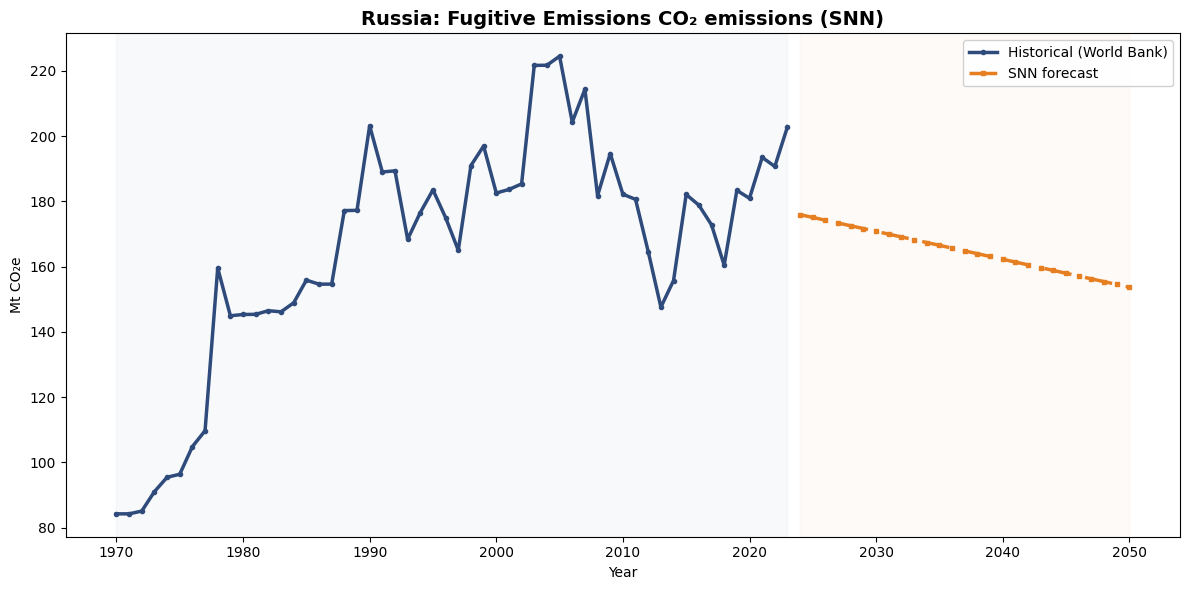

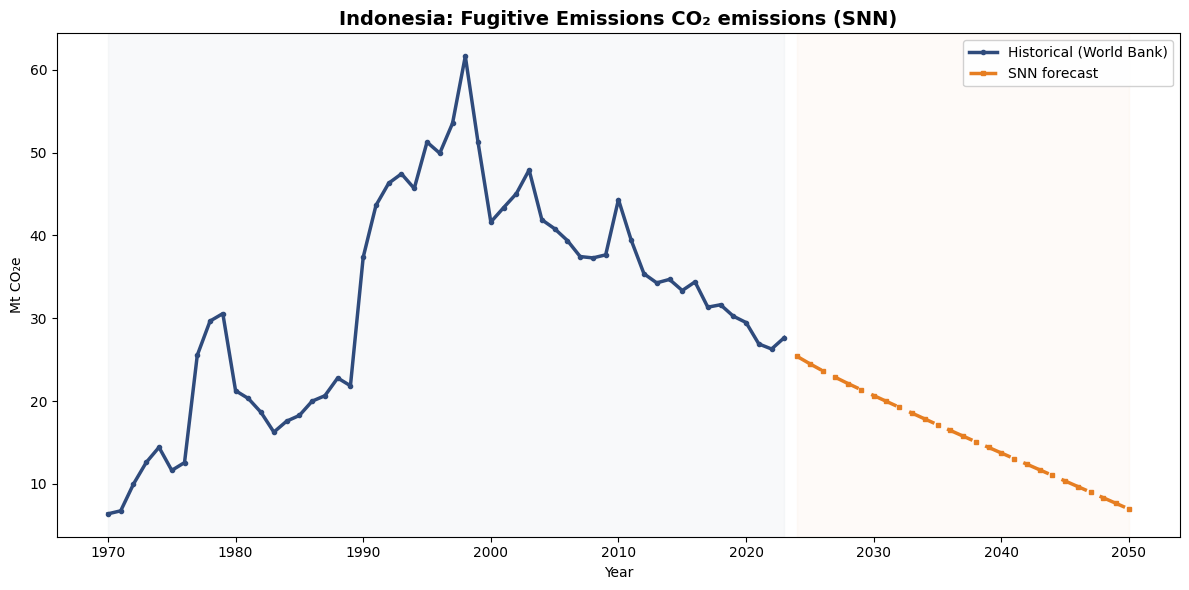

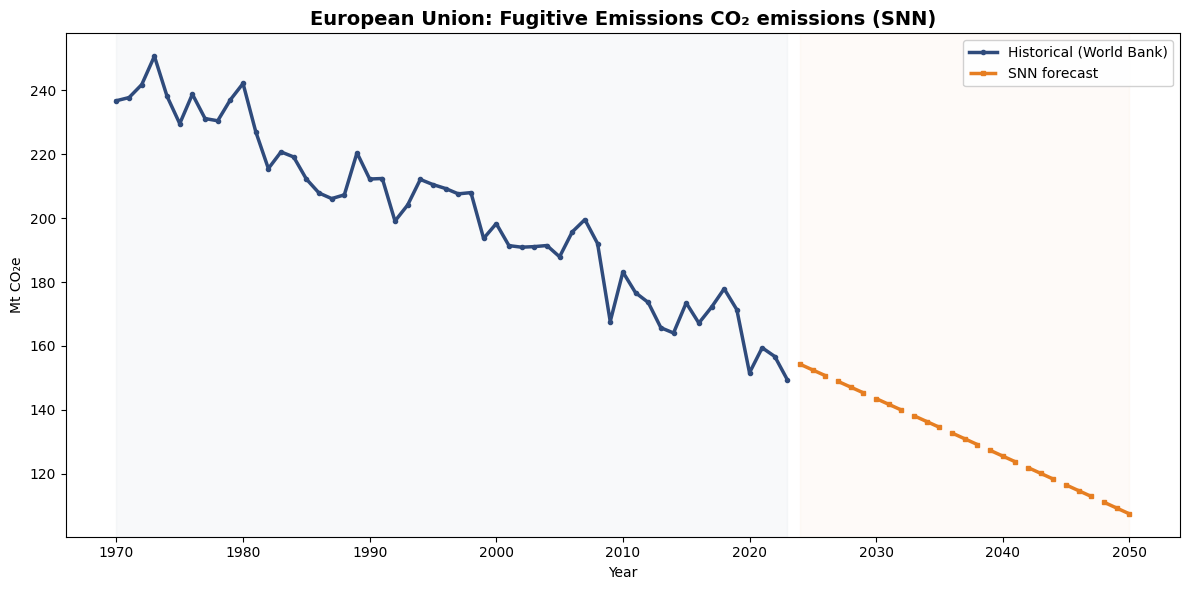

In [15]:
snn_walk_results, snn_walk_forecasts = walkthrough('SNN', fit_predict_snn, color='#E67E22')

### 3.4 All sectors and regions

All 42 series. Because the networks draw their initial weights and mini-batch order from a random
stream, the exact set of passing series can vary between environments; the overall pass count and
the sectors in which the shallow network is competitive are the stable findings.

In [16]:
snn_results = evaluate_model('SNN', fit_predict_snn)
summarize(snn_results, 'Shallow Neural Network (1 x 100)')
snn_results.to_excel(f'{OUTPUT_DIR}/results_SNN.xlsx', index=False)


=== SNN: Agriculture ===
  BRA: train  9.76% | test 10.66% | naive  5.80% | gap +0.90% | fail
  IND: train  7.49% | test  5.36% | naive  3.70% | gap -2.13% | fail
  CHN: train  9.47% | test 35.28% | naive  9.93% | gap +25.80% | fail
  USA: train  3.55% | test  3.95% | naive  3.12% | gap +0.41% | fail
  RUS: train 13.79% | test 45.34% | naive 14.41% | gap +31.55% | fail
  IDN: train 12.11% | test 15.63% | naive  7.78% | gap +3.52% | fail
  EUU: train  6.61% | test 11.20% | naive  4.54% | gap +4.59% | fail

=== SNN: Fugitive Emissions ===
  BRA: train  6.97% | test 17.62% | naive  5.80% | gap +10.65% | fail
  IND: train  6.05% | test 16.15% | naive  3.75% | gap +10.10% | fail
  CHN: train  7.27% | test  4.50% | naive  6.83% | gap -2.77% | PASS
  USA: train  4.85% | test  3.62% | naive  3.38% | gap -1.23% | fail
  RUS: train  6.74% | test 12.18% | naive  6.55% | gap +5.43% | fail
  IDN: train 16.38% | test  3.52% | naive  4.20% | gap -12.86% | PASS
  EUU: train  2.56% | test  4.72% | nai

## 4. Deep Neural Network (PyTorch)

### 4.1 Model

Three hidden layers of 100 ReLU neurons each followed by a linear output, 20,701 trainable
parameters in total, roughly 40× the shallow network.

The additional depth lets the network learn a hierarchy of patterns: the first layer picks up the
basic trend, and deeper layers combine those signals into more complex relationships between the
polynomial features and the temporal dynamics, such as a plateau followed by renewed growth or a sharp
dip and recovery. The expectation is that this flexibility improves forecasting across the varied
emission paths of different regions and sectors. The corresponding risk is that a 20,000-parameter
model trained on 43 points fits noise rather than signal; ReLU activations and feature scaling
mitigate that tendency, and the overfitting test exists precisely to catch it when they do not.

Training uses the utilities of Section 3.1 with the same optimiser, loss, epochs and batch size.

Sequential(
  (0): Linear(in_features=3, out_features=100, bias=True)
  (1): ReLU()
  (2): Linear(in_features=100, out_features=100, bias=True)
  (3): ReLU()
  (4): Linear(in_features=100, out_features=100, bias=True)
  (5): ReLU()
  (6): Linear(in_features=100, out_features=1, bias=True)
)
Trainable parameters: 20701

Training trace: Brazil, Fugitive Emissions:
    epoch  20/100  loss 0.0799
    epoch  40/100  loss 0.0714
    epoch  60/100  loss 0.0572
    epoch  80/100  loss 0.0488
    epoch 100/100  loss 0.0478


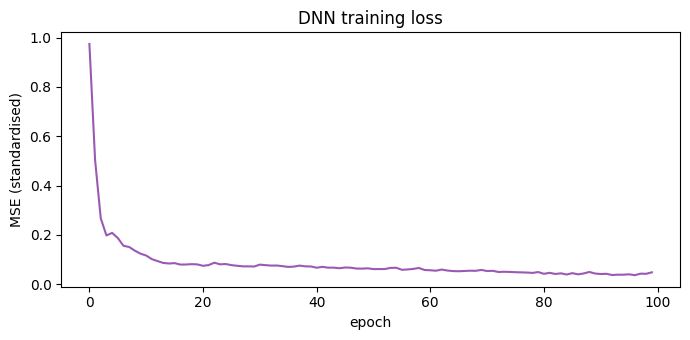

In [17]:
set_seed()
_dnn = build_mlp(POLY_DEGREE, DNN_HIDDEN_LAYERS)
print(_dnn)
print('Trainable parameters:', sum(p.numel() for p in _dnn.parameters()))

print(f'\nTraining trace: {COUNTRY_NAMES[REGIONS[0]]}, {WALKTHROUGH_SECTOR.replace("_", " ")}:')
_hist = train_mlp(_dnn, _xs.transform(_X_tr), _ys.transform(_y_tr.values.reshape(-1, 1)).ravel(), verbose=True)
plt.figure(figsize=(7, 3.5)); plt.plot(_hist, color='#9B59B6'); plt.xlabel('epoch'); plt.ylabel('MSE (standardised)')
plt.title('DNN training loss'); plt.tight_layout(); plt.show()

### 4.2 Single-sector walkthrough

Same procedure as for the shallow network, with the three-layer architecture.

DNN, Fugitive Emissions (1970-2023, 43 training years, 11 test years)

Test-set performance against the naive benchmark:
       Country Train_MAPE Test_MAPE Naive_Test_MAPE Overfitting_Gap  Model_Success
        Brazil      6.42%    26.14%           5.80%          19.72%          False
         India      4.62%    21.52%           3.75%          16.90%          False
         China      6.33%    13.62%           6.83%           7.30%          False
 United States      2.85%     4.74%           3.38%           1.89%          False
        Russia      4.46%    14.66%           6.55%          10.20%          False
     Indonesia      9.32%     3.83%           4.20%          -5.50%           True
European Union      2.08%     3.60%           4.50%           1.52%           True

Average test MAPE: 12.59% | best: European Union (3.60%) | worst: Brazil (26.14%)

Refitting on the full history and forecasting 2024-2050 ...


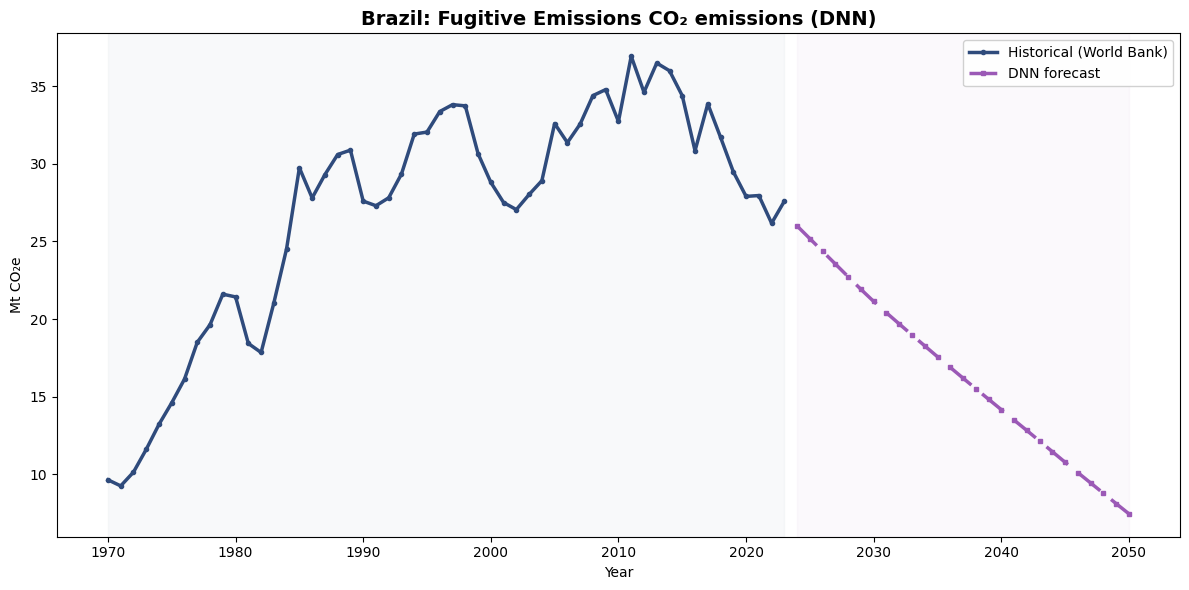

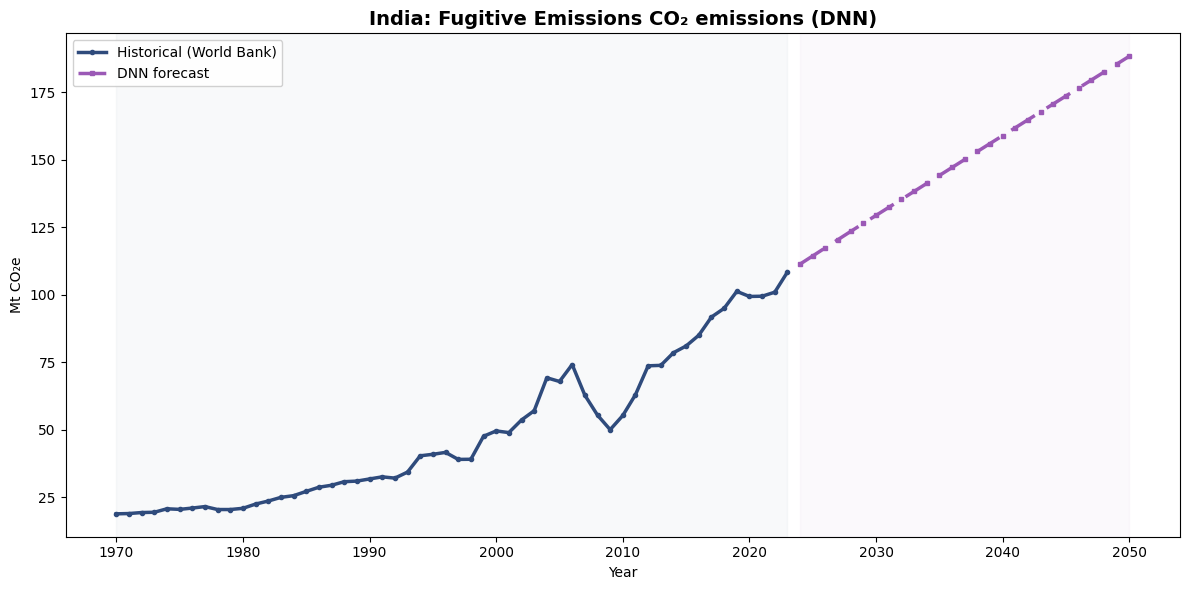

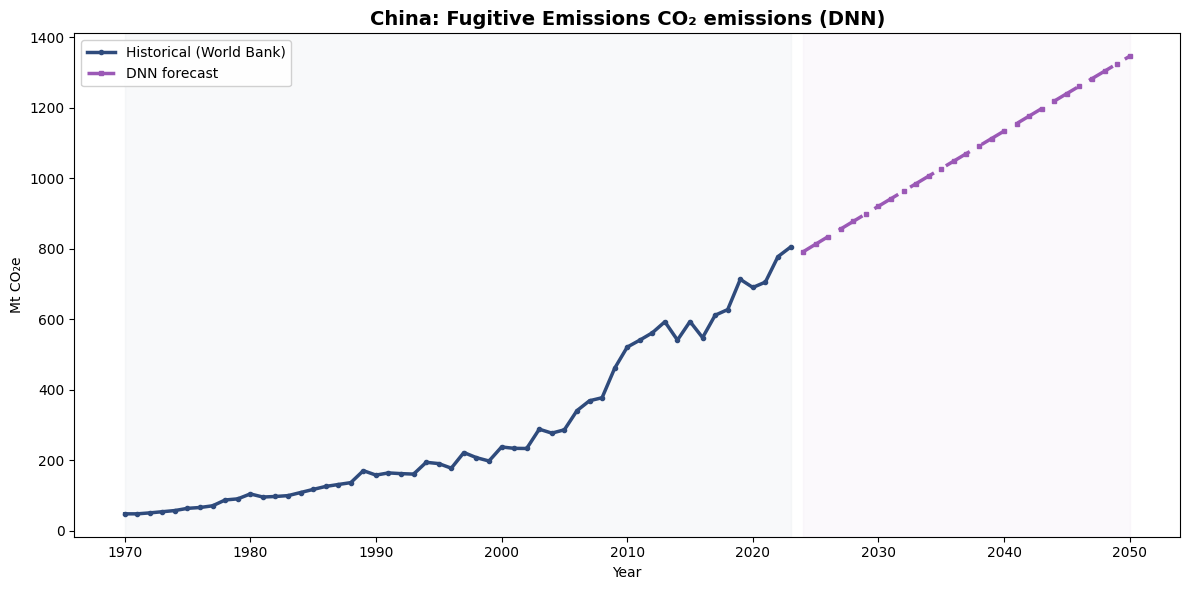

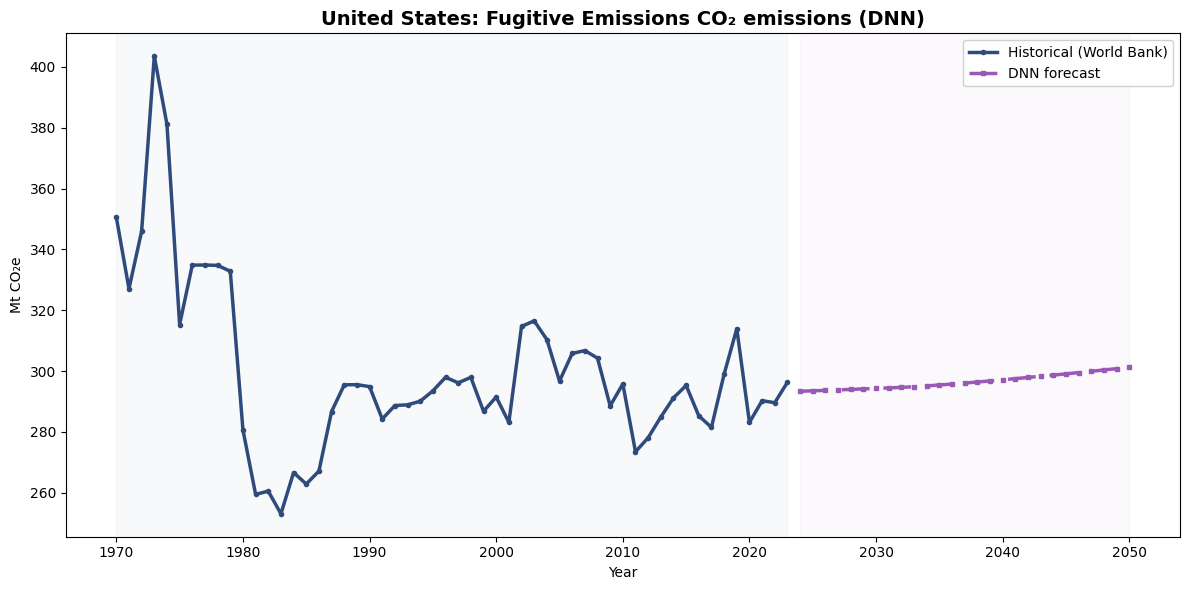

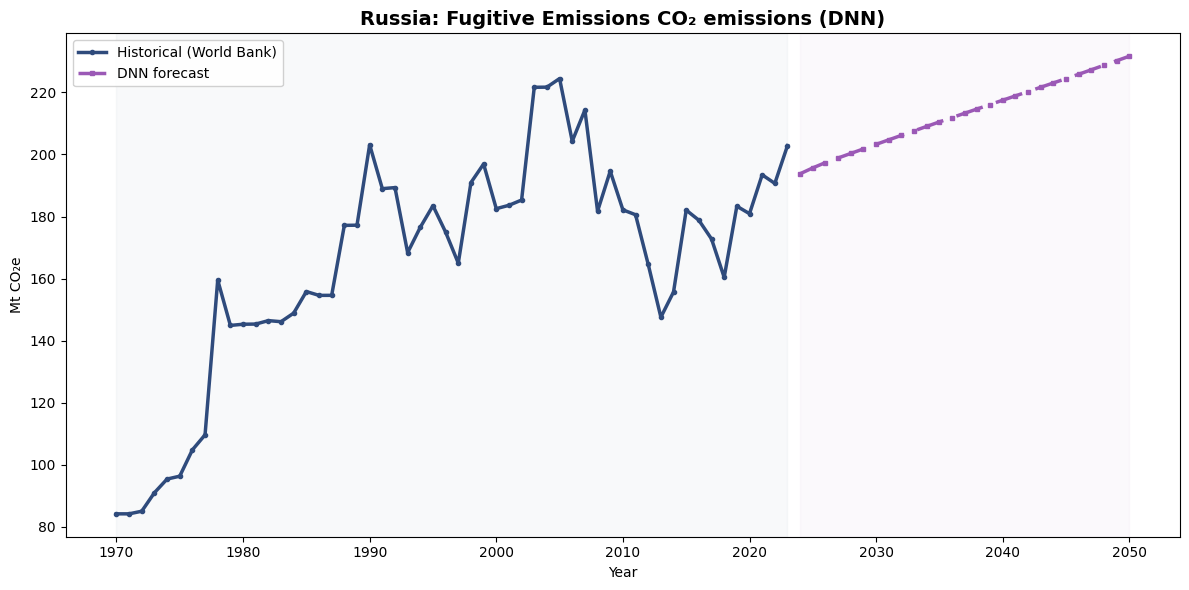

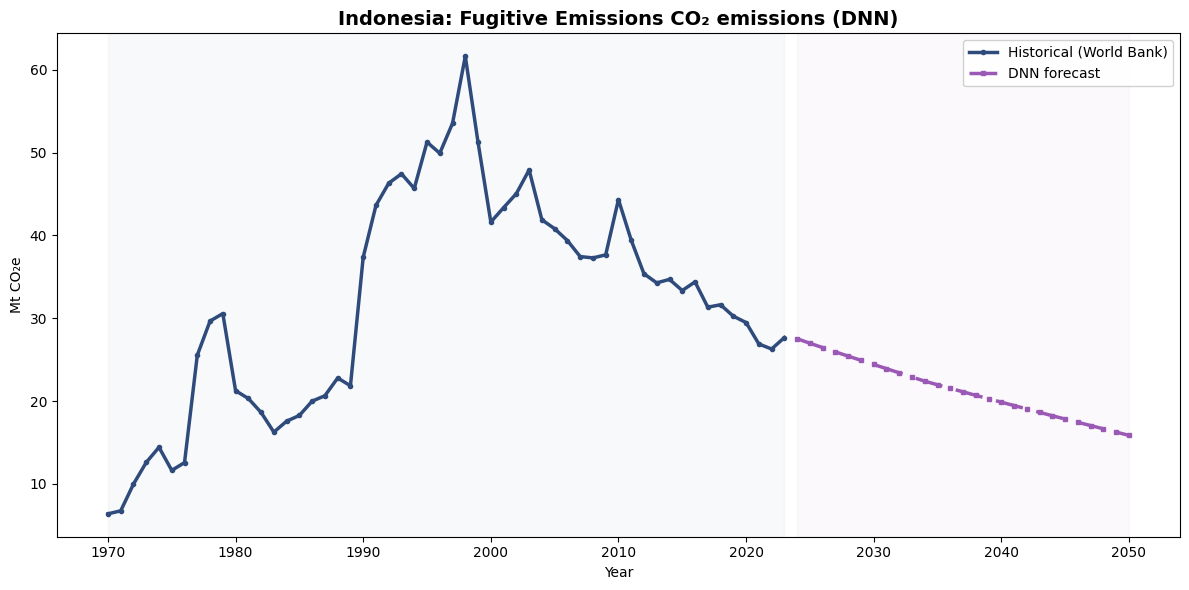

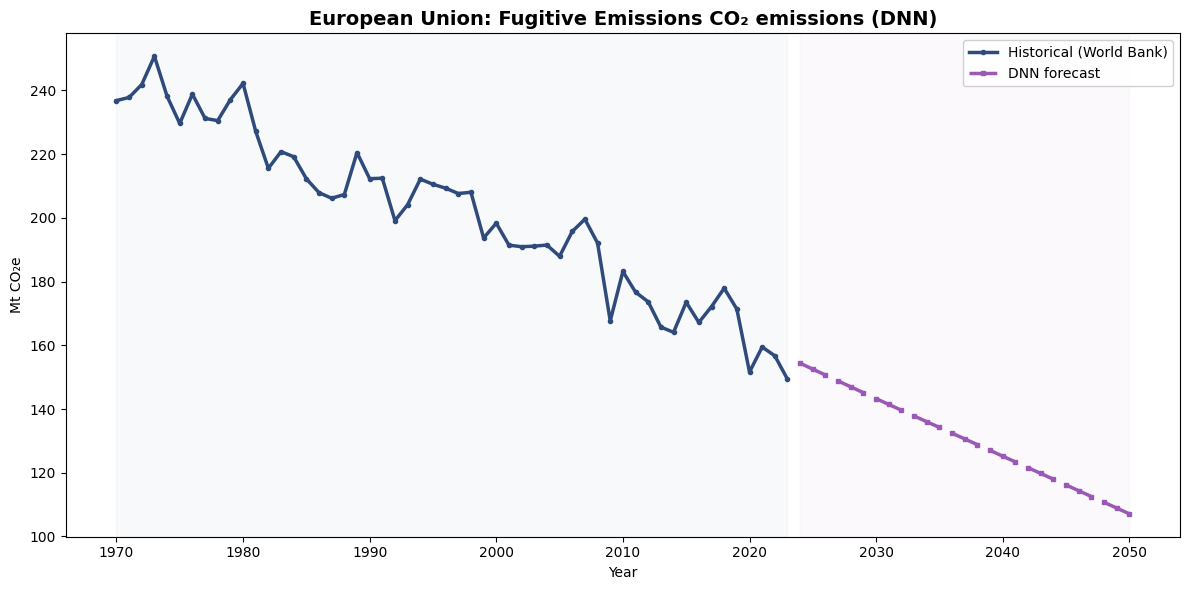

In [18]:
dnn_walk_results, dnn_walk_forecasts = walkthrough('DNN', fit_predict_dnn, color='#9B59B6')

### 4.3 All sectors and regions

All 42 series.

In [19]:
dnn_results = evaluate_model('DNN', fit_predict_dnn)
summarize(dnn_results, 'Deep Neural Network (3 x 100)')
dnn_results.to_excel(f'{OUTPUT_DIR}/results_DNN.xlsx', index=False)


=== DNN: Agriculture ===
  BRA: train  9.23% | test 13.15% | naive  5.80% | gap +3.92% | fail
  IND: train  4.90% | test 12.31% | naive  3.70% | gap +7.41% | fail
  CHN: train  8.72% | test 18.70% | naive  9.93% | gap +9.97% | fail
  USA: train  3.41% | test  4.50% | naive  3.12% | gap +1.09% | fail
  RUS: train  2.67% | test 20.76% | naive 14.41% | gap +18.09% | fail
  IDN: train  9.25% | test 18.46% | naive  7.78% | gap +9.21% | fail
  EUU: train  2.41% | test 10.88% | naive  4.54% | gap +8.47% | fail

=== DNN: Fugitive Emissions ===
  BRA: train  6.42% | test 26.14% | naive  5.80% | gap +19.72% | fail
  IND: train  4.62% | test 21.52% | naive  3.75% | gap +16.90% | fail
  CHN: train  6.33% | test 13.62% | naive  6.83% | gap +7.30% | fail
  USA: train  2.85% | test  4.74% | naive  3.38% | gap +1.89% | fail
  RUS: train  4.46% | test 14.66% | naive  6.55% | gap +10.20% | fail
  IDN: train  9.32% | test  3.83% | naive  4.20% | gap -5.50% | PASS
  EUU: train  2.08% | test  3.60% | naiv

## 5. Cross-model comparison

### 5.1 Which models pass where

A pass/fail matrix over all 42 sector–region series and the four models, followed by the series
for which more than one model passes. Agreement between models built on different principles, say a
statistical autoregression and a neural network, provides additional confidence in a forecast,
and such series are the natural candidates for any further inter-regional analysis.

In [20]:
MODEL_ORDER = ['LR', 'ARIMA', 'SNN', 'DNN']
all_results = pd.concat([lr_results, arima_results, snn_results, dnn_results], ignore_index=True)
all_results.to_excel(f'{OUTPUT_DIR}/results_all_models.xlsx', index=False)

success_matrix = (all_results.pivot_table(index=['Sector', 'Country'], columns='Model',
                                          values='Model_Success', aggfunc='first')
                  .reindex(columns=MODEL_ORDER).fillna(False).astype(bool))
test_mape_matrix = (all_results.pivot_table(index=['Sector', 'Country'], columns='Model',
                                            values='Test_MAPE', aggfunc='first')
                    .reindex(columns=MODEL_ORDER))
naive = all_results.groupby(['Sector', 'Country'])['Naive_Test_MAPE'].first()

print('Pass (✓) / fail (·) by model; test MAPE shown in brackets, naive benchmark in last column\n')
header = f'{"Sector":<22}{"Region":<16}' + ''.join(f'{m:>16}' for m in MODEL_ORDER) + f'{"Naive":>10}'
print(header); print('-' * len(header))
for (sector, country), row in success_matrix.iterrows():
    cells_ = ''.join(f'{("✓" if row[m] else "·")} ({test_mape_matrix.loc[(sector, country), m]:6.1%}) '.rjust(16)
                     for m in MODEL_ORDER)
    print(f'{sector.replace("_", " "):<22}{country:<16}{cells_}{naive.loc[(sector, country)]:>9.1%}')

print('\nModels passing per model:')
for m in MODEL_ORDER:
    print(f'  {m:<6} {int(success_matrix[m].sum()):>2}/{len(success_matrix)}')
print(f'\nSector-region pairs with at least one passing model: '
      f'{int(success_matrix.any(axis=1).sum())}/{len(success_matrix)}')

multi = success_matrix[success_matrix.sum(axis=1) > 1]
print('\nPairs where more than one model passes:')
for (sector, country), row in multi.iterrows():
    print(f'  {sector.replace("_", " "):<22} {country:<16} {", ".join(m for m in MODEL_ORDER if row[m])}')

success_matrix.to_excel(f'{OUTPUT_DIR}/success_matrix.xlsx')

Pass (✓) / fail (·) by model; test MAPE shown in brackets, naive benchmark in last column

Sector                Region                        LR           ARIMA             SNN             DNN     Naive
----------------------------------------------------------------------------------------------------------------
Agriculture           Brazil               · (  8.1%)      · (  7.9%)      · ( 10.7%)      · ( 13.2%)      5.8%
Agriculture           China                · ( 35.1%)      · ( 34.4%)      · ( 35.3%)      · ( 18.7%)      9.9%
Agriculture           European Union       · ( 76.3%)      · ( 71.6%)      · ( 11.2%)      · ( 10.9%)      4.5%
Agriculture           India                · (  7.9%)      · (  8.1%)      · (  5.4%)      · ( 12.3%)      3.7%
Agriculture           Indonesia            · ( 25.4%)      · ( 25.8%)      · ( 15.6%)      · ( 18.5%)      7.8%
Agriculture           Russia               · ( 81.2%)      · ( 74.0%)      · ( 45.3%)      · ( 20.8%)     14.4%
Agriculture

### 5.2 Average performance by model and by sector

Mean test MAPE per model (lower is better) and the number of passes per sector, to show where each
model family is competitive.

Mean test MAPE by model (all 42 series):
         mean  median    min     max
Model                               
LR     31.95%  25.33%  4.24%  95.53%
ARIMA  31.11%  27.70%  4.29%  89.40%
SNN    15.26%  11.16%  3.52%  45.34%
DNN    14.08%  12.31%  2.84%  43.75%

Naive benchmark mean test MAPE: 5.59%

Passes by sector and model:
Model                  LR  ARIMA  SNN  DNN  Any
Sector                                         
Agriculture             0      0    0    0    0
Fugitive_Emissions      1      1    2    2    4
Industrial_Combustion   0      0    0    1    1
Industrial_Processes    0      0    0    1    1
Power                   1      1    0    2    3
Transportation          0      0    0    1    1


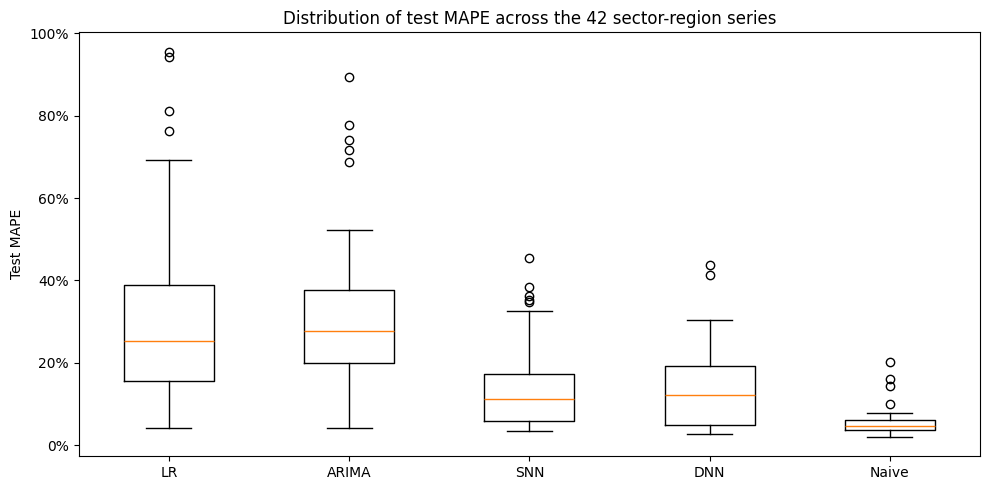

In [21]:
print('Mean test MAPE by model (all 42 series):')
print(all_results.groupby('Model')['Test_MAPE'].agg(['mean', 'median', 'min', 'max'])
      .reindex(MODEL_ORDER).map('{:.2%}'.format).to_string())
print(f'\nNaive benchmark mean test MAPE: {naive.mean():.2%}')

print('\nPasses by sector and model:')
by_sector = (all_results.pivot_table(index='Sector', columns='Model', values='Model_Success', aggfunc='sum')
             .reindex(columns=MODEL_ORDER).astype(int))
by_sector['Any'] = success_matrix.groupby(level='Sector').any().sum(axis=1).astype(int)
print(by_sector.to_string())

fig, ax = plt.subplots(figsize=(10, 5))
box_labels = MODEL_ORDER + ['Naive']
box_data = [test_mape_matrix[m].dropna().values for m in MODEL_ORDER] + [naive.dropna().values]
ax.boxplot(box_data)
ax.set_xticks(range(1, len(box_labels) + 1)); ax.set_xticklabels(box_labels)
ax.set_title('Distribution of test MAPE across the 42 sector-region series')
ax.set_ylabel('Test MAPE')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
plt.tight_layout(); plt.show()

### 5.3 2024 forecasts from every model

Each model is refitted on the full 1970–2023 history for every sector–region pair and asked for
its first out-of-sample year. This table is produced for *all* 168 model–series combinations, with the
pass/fail status attached, so that both successful and unsuccessful forecasts can be inspected.

In [22]:
FIT_PREDICT = {'LR': fit_predict_lr, 'ARIMA': fit_predict_arima,
               'SNN': fit_predict_snn, 'DNN': fit_predict_dnn}

rows = []
for sector, df in DATA.items():
    print(f'Forecasting {sector.replace("_", " ")} ...')
    for region in df.columns:
        if chronological_split(df, region) is None:
            continue
        for model_name, fp in FIT_PREDICT.items():
            fc = forecast_full_history(fp, df, region)
            passed = bool(success_matrix.loc[(sector, COUNTRY_NAMES[region]), model_name])
            rows.append({'Sector': sector, 'Sector_Code': SECTOR_ABBREV[sector], 'Region': region,
                         'Country': COUNTRY_NAMES[region], 'Model': model_name,
                         'Passed_Tests': passed, 'Last_Actual_2023': df[region].loc[END_YEAR],
                         **{f'Forecast_{yr}': fc.loc[yr] for yr in (2024, 2025, 2030, 2040, 2050)}})

forecasts_2024 = pd.DataFrame(rows)
forecasts_2024.to_excel(f'{OUTPUT_DIR}/forecasts_all_models.xlsx', index=False)

print('\n2024 forecast (Mt CO2e) by model; * marks a model that passed both tests for that series\n')
table = forecasts_2024.pivot_table(index=['Sector_Code', 'Region'], columns='Model', values='Forecast_2024') \
                      .reindex(columns=MODEL_ORDER)
flags = forecasts_2024.pivot_table(index=['Sector_Code', 'Region'], columns='Model', values='Passed_Tests',
                                   aggfunc='first').reindex(columns=MODEL_ORDER)
pretty = table.copy().astype(object)
for m in MODEL_ORDER:
    pretty[m] = [f'{v:,.2f}{"*" if f else ""}' for v, f in zip(table[m], flags[m])]
pretty.insert(0, 'Actual_2023', forecasts_2024.groupby(['Sector_Code', 'Region'])['Last_Actual_2023']
              .first().map('{:,.2f}'.format))
print(pretty.to_string())

Forecasting Agriculture ...
Forecasting Fugitive Emissions ...
Forecasting Industrial Combustion ...
Forecasting Industrial Processes ...
Forecasting Power ...
Forecasting Transportation ...

2024 forecast (Mt CO2e) by model; * marks a model that passed both tests for that series

Model              Actual_2023        LR     ARIMA       SNN        DNN
Sector_Code Region                                                     
AG          BRA          12.94     13.45     13.47     12.47      13.06
            CHN          16.64     10.63     12.68     15.50      15.20
            EUU           8.53     12.19      8.67     10.34       9.82
            IDN           4.82      5.60      5.12      6.05       5.37
            IND          31.92     31.49     32.12     31.83      31.90
            RUS           8.19      9.96      9.23      7.31       8.05
            USA           6.80      6.89      6.87      6.98       7.10
FE          BRA          27.59     27.91     27.21     30.56      25.9

### 5.4 Out-of-sample validation against 2024 actuals

If the World Bank has published 2024 values, every passing model's 2024 forecast is scored against
them. This is the true test of the selection rule: a model that passed on 1970–2023 data should also
be accurate on a year it never saw.

In [23]:
print('Downloading 2024 actuals ...')
actual_2024 = {}
for sector, code in INDICATORS.items():
    try:
        df24 = download_sector(code, start=END_YEAR + 1, end=END_YEAR + 1)
        if len(df24) and df24.notna().any().any():
            actual_2024[sector] = df24.iloc[0]
            print(f'  {sector:<22} available for {int(df24.iloc[0].notna().sum())} regions')
        else:
            print(f'  {sector:<22} not yet published')
    except Exception as exc:
        print(f'  {sector:<22} unavailable ({exc})')

if actual_2024:
    val = forecasts_2024.copy()
    val['Actual_2024'] = [actual_2024.get(s, pd.Series(dtype=float)).get(r, np.nan)
                          for s, r in zip(val['Sector'], val['Region'])]
    val = val.dropna(subset=['Actual_2024'])
    val['APE_2024'] = (val['Forecast_2024'] - val['Actual_2024']).abs() / val['Actual_2024']
    val['Naive_APE_2024'] = (val['Last_Actual_2023'] - val['Actual_2024']).abs() / val['Actual_2024']

    passed = val[val['Passed_Tests']].sort_values(['Model', 'Sector_Code', 'Region'])
    print(f'\nModels that passed both tests: 2024 forecast vs actual ({len(passed)} model-series):\n')
    show = passed[['Model', 'Sector_Code', 'Region', 'Actual_2024', 'Forecast_2024', 'APE_2024', 'Naive_APE_2024']].copy()
    for c in ['Actual_2024', 'Forecast_2024']:
        show[c] = show[c].map('{:,.2f}'.format)
    for c in ['APE_2024', 'Naive_APE_2024']:
        show[c] = show[c].map('{:.2%}'.format)
    print(show.to_string(index=False))

    print('\nMean absolute percentage error on 2024, by model:')
    summary = val.groupby(['Model', 'Passed_Tests'])['APE_2024'].agg(['mean', 'count'])
    summary['mean'] = summary['mean'].map('{:.2%}'.format)
    print(summary.to_string())
    print(f'\nNaive (2023 value carried forward): {val["Naive_APE_2024"].mean():.2%} over {val["Region"].nunique() * val["Sector"].nunique()} series')
    val.to_excel(f'{OUTPUT_DIR}/validation_2024.xlsx', index=False)
else:
    print('\n2024 data not yet available from the World Bank; re-run this cell once it is published.')

  Agriculture            available for 7 regions
  Fugitive_Emissions     available for 7 regions
  Industrial_Combustion  available for 7 regions
  Industrial_Processes   available for 7 regions
  Power                  available for 7 regions
  Transportation         available for 7 regions

Models that passed both tests: 2024 forecast vs actual (13 model-series):

Model Sector_Code Region Actual_2024 Forecast_2024 APE_2024 Naive_APE_2024
ARIMA          FE    EUU      146.29        149.35    2.09%          2.09%
ARIMA          PI    IDN      350.52        336.44    4.01%          5.43%
  DNN          FE    EUU      146.29        154.35    5.51%          2.09%
  DNN          FE    IDN       27.97         27.52    1.62%          1.13%
  DNN          IC    IND      689.15        647.63    6.02%          4.24%
  DNN          IP    IND      258.48        233.04    9.84%          4.79%
  DNN          PI    CHN    6,577.95      6,084.56    7.50%          1.40%
  DNN          PI    IND    1,

### 5.5 Output files

All tables and figures written by this notebook are in the `outputs/` folder:

| File | Contents |
|------|----------|
| `co2_sector_data_1970_2023.xlsx` | Raw World Bank data, one sheet per sector |
| `results_LR.xlsx`, `results_ARIMA.xlsx`, `results_SNN.xlsx`, `results_DNN.xlsx` | Per-model train/test/naive MAPE and pass/fail for all 42 series |
| `results_all_models.xlsx`, `success_matrix.xlsx` | Combined results and the pass/fail matrix |
| `<Model>_<Sector>_forecasts_2024_2050.xlsx` | Walkthrough-sector forecasts to 2050 |
| `forecasts_all_models.xlsx` | 2024/2025/2030/2040/2050 forecasts for every model and series |
| `validation_2024.xlsx` | Forecast-vs-actual comparison for 2024 (when published) |
| `*.png` | Forecast plots |

In [24]:
print('Files written:')
for name in sorted(os.listdir(OUTPUT_DIR)):
    print(f'  {name}')

Files written:
  ARIMA_Fugitive_Emissions_forecasts_2024_2050.xlsx
  DNN_Fugitive_Emissions_forecasts_2024_2050.xlsx
  Fugitive_Emissions_BRA_ARIMA_forecast.png
  Fugitive_Emissions_BRA_DNN_forecast.png
  Fugitive_Emissions_BRA_Linear_Regression_forecast.png
  Fugitive_Emissions_BRA_SNN_forecast.png
  Fugitive_Emissions_CHN_ARIMA_forecast.png
  Fugitive_Emissions_CHN_DNN_forecast.png
  Fugitive_Emissions_CHN_Linear_Regression_forecast.png
  Fugitive_Emissions_CHN_SNN_forecast.png
  Fugitive_Emissions_EUU_ARIMA_forecast.png
  Fugitive_Emissions_EUU_DNN_forecast.png
  Fugitive_Emissions_EUU_Linear_Regression_forecast.png
  Fugitive_Emissions_EUU_SNN_forecast.png
  Fugitive_Emissions_IDN_ARIMA_forecast.png
  Fugitive_Emissions_IDN_DNN_forecast.png
  Fugitive_Emissions_IDN_Linear_Regression_forecast.png
  Fugitive_Emissions_IDN_SNN_forecast.png
  Fugitive_Emissions_IND_ARIMA_forecast.png
  Fugitive_Emissions_IND_DNN_forecast.png
  Fugitive_Emissions_IND_Linear_Regression_forecast.png
  Fug